##### In this Python notebook, I will be loading the cifar-10 dataset, through torchvision.datasets, and I will create a Convolutional Neural Network model, and train that model, and evaluate it and try to improve it's accuracy using different data augmentation techniques

In [1]:
# Importing all the libraries required, like torch,torchvision for datasets and making the model, pandas and matplotlib to visualise the data, and some others to help us create a well rounded model
import torch 
import matplotlib.pyplot as plt
import torchvision
import torchmetrics
import pandas as pd 

from torchmetrics import ConfusionMatrix
from mlxtend.plotting import plot_confusion_matrix
from torch import nn
from torchvision import datasets
from torchvision.transforms import ToTensor 
from torch.utils.data import DataLoader
from pathlib import Path
from torchvision.transforms import v2

from timeit import default_timer as timer

In [2]:
# Creating train_data, val_data and test_data. First we will only be using train and testing data, later we will be using validation data
# one more thing that I came across the pytorch documentation, was that v2 is recommended over transforms, and that ToTensor is deprecated, and to use Compose of ToImage and ToDtype with dtype set as defualt torch float32
train_data = datasets.CIFAR10(root="data",
                            train=True,
                            download=True,
                            transform=v2.Compose([v2.ToImage(),
                                                v2.ToDtype(dtype=torch.float,scale=True),    # We did scale = True, so that we don't get exploding gradients, as the colour intensity is from 0 to 255, and if we don't apply scale and then normalize the it would be a huge value at one end which would cause the weignts to be handled incorrectly. 
                                                v2.Normalize(mean=[0.4914,0.4822,0.4465],std=[0.2470,0.2435,0.2616])]))
val_data = datasets.CIFAR10(root="data",
                            train=True,
                            download=True,
                            transform=v2.Compose([v2.ToImage(),
                                                v2.ToDtype(dtype=torch.float,scale=True), 
                                                v2.Normalize(mean=[0.4914,0.4822,0.4465],std=[0.2470,0.2435,0.2616])])) 

test_data = datasets.CIFAR10(root="data",
                            train=False,
                            download=True,
                            transform=v2.Compose([v2.ToImage(),
                                                v2.ToDtype(dtype=torch.float,scale=True), 
                                                v2.Normalize(mean=[0.4914,0.4822,0.4465],std=[0.2470,0.2435,0.2616])])) 

Files already downloaded and verified
Files already downloaded and verified
Files already downloaded and verified


In [3]:
BATCH_SIZE = 128
train_dataloader = DataLoader(dataset=train_data,
                              batch_size=BATCH_SIZE,
                              shuffle=True,     #So that the model tries to learn the actual pattern, rather than learning the locations of the images
                              num_workers=2,    #More num_workers means more sub processes, which helps in decreasing the time taken to run
                              pin_memory=True,  #Helps push data in a faster manner, from the CPU to GPU, by pairing with non_blovking=True in .to(device), it lets GPU fetch the data from CPU while the current process is running  
                              persistent_workers=True
)

test_dataloader = DataLoader(dataset=test_data,
                            batch_size=BATCH_SIZE,
                            shuffle=False,
                            num_workers=2,
                            pin_memory=True,
                            persistent_workers=True)

In [4]:
image_batch,label_batch = next(iter(train_dataloader))
print(image_batch.shape)

torch.Size([128, 3, 32, 32])


In [5]:
print(label_batch[:10])

tensor([2, 8, 5, 2, 4, 5, 5, 9, 7, 5])


##### Let' visualise our data by plotting some images from our data using matplotlib

In [6]:
class_names = train_data.classes
print(class_names)

['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


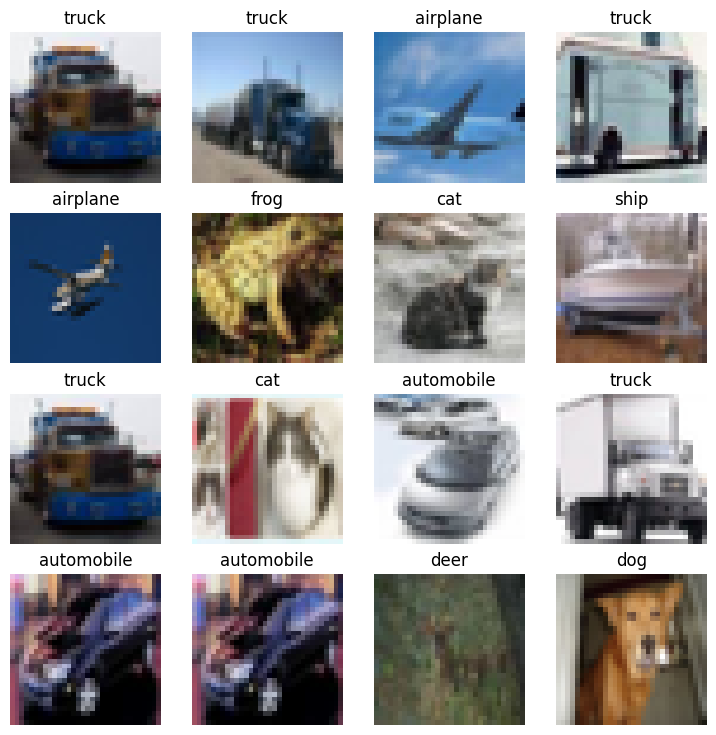

In [7]:
torch.manual_seed(42)     # For reproducibility
fig = plt.figure(figsize=(9,9))
rows,cols=4,4
for i in range(1,rows*cols+1):
    random_idx = torch.randint(0,len(image_batch),size=[1]).item()
    img,label = image_batch[random_idx], label_batch[random_idx]     #Randomly selecting images and their labels from the first batch
    np_image = img.permute(1,2,0)     #PyTorch works as NCHW but Matplotlib requires either only height and width or NHWC
    mean = torch.tensor([0.4914, 0.4822, 0.4465])  
    std = torch.tensor([0.2470, 0.2435, 0.2616])
    #While I was running this after adding normalization, matplotlib gave me warnings saying that Clipping input data to the valid range for imshow with RGB data, and then I discovered that, matplotlib expects the colour brightness values to be between 0 and 255, the default, and since we normalized now they are not, so we need to convert them back, and so thats what we are doing in this temporary np_image variable
    np_image = np_image * std + mean    #So we convert the pixel activation values back to the standard form so matplotlib can work with it. Matplotlib automatically converts those even if we don't do it, but it gives us warnings
    fig.add_subplot(rows,cols,i)
    plt.imshow(np_image)
    plt.title(class_names[label])
    plt.axis(False)

In [8]:
# So first let's set up device agnostic code:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


##### Let's now build the architecture of our model. I will first create a Linear activations only model, as my baseline model and then I will try to imrpove it

In [9]:
class LinearModel(nn.Module):
    def __init__(self,
                input_shape:int,
                hidden_units:int,
                output_shape:int):
        super().__init__()
        self.LinearLayerStack = nn.Sequential(
            nn.Flatten(),  
            nn.Linear(in_features=input_shape,
                     out_features=hidden_units),
            nn.Linear(in_features=hidden_units,
                      out_features=hidden_units),
            nn.Linear(in_features=hidden_units,
                      out_features=output_shape)
        )

    def forward(self,x):
        return self.LinearLayerStack(x)

In [10]:
#Setting a model up
model_0 = LinearModel(input_shape = 3*32*32,
                     hidden_units=128,
                     output_shape=len(class_names)).to(device)
print(model_0)

LinearModel(
  (LinearLayerStack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=128, bias=True)
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [11]:
# Setup loss function, optimizer and accuracy_fn(Evaluation metrics) 
loss_fn = nn.CrossEntropyLoss()       #Cross Entropy loss function is used for multiclass classifications

optimizer = torch.optim.Adam(params=model_0.parameters(), lr=0.001)

def accuracy_fn(y_true,y_pred):                      #Retruns (correct preds/total preds) percent 
    correct = torch.eq(y_true, y_pred).sum().item()
    acc = (correct / len(y_pred)) * 100
    return acc

In [12]:
#creating a timer, to find the time taken for training
def print_train_time(start, end, device=None):
    total_time = end - start
    print(f"\nTrain time on {device}: {total_time:.3f} seconds")
    return total_time

In [13]:
def train_step(model:torch.nn.Module,
              data_loader:torch.utils.data.DataLoader,
              optimizer: torch.optim.Optimizer,
              loss_fn:torch.nn.Module,
              accuracy_fn,
              device:torch.device = device):

    train_loss,train_acc = 0,0
    model.train()
    for (X,y) in data_loader:
        X,y = X.to(device,non_blocking=True),y.to(device,non_blocking=True)

        #1 Forward pass
        y_pred = model(X)

        #2 Calculate loss and accuracy 
        loss = loss_fn(y_pred,y)
        train_loss+=loss.item()     # we use .item(), as it converts the final single valued tensor to a python datatype, so it helps fasten our code, as if we don't do this then train_loss would remember history of each batch, and it would continue on to the next batches. However, we make sure not to do the .item() directly in the above step, as we want the loss variable to know the past history for backpropogation(loss.backward) to work, but dont need the history for loss calculation
        train_acc += accuracy_fn(y_true = y, y_pred=y_pred.argmax(dim=1))   #argmax because we want the labels, not the raw logits, as that's what our accuracy_fn expects

        #3 Optimizer zero grad
        optimizer.zero_grad()

        #4. Loss backwards(backpropogation)
        loss.backward()

        #5. Optimizer step(Gradient Descent)
        optimizer.step()

    train_loss /= len(data_loader)    #calculating the metrics per batch
    train_acc /= len(data_loader)

    print(f"Training Loss: {train_loss:.4f} |  Training Accuracy: {train_acc:.2f}%") 

In [14]:
def test_step(model:torch.nn.Module,
             data_loader:torch.utils.data.DataLoader,
             loss_fn:torch.nn.Module,
             accuracy_fn,
             device:torch.device=device):

    test_loss,test_acc=0,0
    model.to(device)
    model.eval()
    with torch.inference_mode():
        for X_test,y_test in data_loader:
            X_test,y_test=X_test.to(device),y_test.to(device)
            
            #1 Forward pass
            y_test_pred = model(X_test)

            #2 Calculate loss and accuracy 
            loss = loss_fn(y_test_pred, y_test)
            test_loss += loss.item()
            test_acc+=accuracy_fn(y_true=y_test,y_pred=y_test_pred.argmax(dim=1))

        test_loss /=len(data_loader)
        test_acc /=len(data_loader)
        print(f"Testing Loss: {test_loss:.4f} |  Testing Accuracy: {test_acc:.2f}%") 

In [15]:
#Running the training and testing loop on model_0
torch.manual_seed(42)
torch.cuda.manual_seed(42)

train_time_start = timer()
epochs = 3
for epoch in range(epochs):
    print(f"Epoch {epoch}\n--------")
    train_step(model=model_0, data_loader=train_dataloader,optimizer=optimizer,loss_fn=loss_fn,accuracy_fn=accuracy_fn,device=device)

    test_step(model=model_0,data_loader=test_dataloader,loss_fn=loss_fn,accuracy_fn=accuracy_fn,device=device)

train_time_end = timer()
total_train_time_on_model_0 = print_train_time(start=train_time_start,end=train_time_end,device=device)

Epoch 0
--------
Training Loss: 1.8403 |  Training Accuracy: 35.78%
Testing Loss: 1.7681 |  Testing Accuracy: 37.77%
Epoch 1
--------
Training Loss: 1.7659 |  Training Accuracy: 38.74%
Testing Loss: 1.7589 |  Testing Accuracy: 37.89%
Epoch 2
--------
Training Loss: 1.7369 |  Training Accuracy: 40.13%
Testing Loss: 1.7568 |  Testing Accuracy: 38.91%

Train time on cuda: 30.735 seconds


##### As we can see the accuracy is really really bad. It was expected as our model architecture comrpised only of linear activation functions only, and the images have non linear aspects to them
##### So let's now make another architecture with a combination of linear and non linear activation functions and see how that works

In [16]:
class LinearAndNonLinearModel(nn.Module):
    def __init__(self,
                input_shape:int,
                hidden_units:int,
                output_shape:int):
        super().__init__()
        self.LayerStack = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=input_shape,
                      out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units,
                      out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units,
                      out_features=output_shape)
        )

    def forward(self,x):
        return self.LayerStack(x)

In [17]:
#Instantiating a model
model_1 = LinearAndNonLinearModel(input_shape=3*32*32,
                                 hidden_units=128,
                                 output_shape=len(class_names)).to(device)
print(model_1)

LinearAndNonLinearModel(
  (LayerStack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [18]:
# Setting up evaluating metrics
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_1.parameters(),
                            lr=0.001)
#accuracy_fn is defined earlier, it's going to remain the same for all

In [19]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

train_time_start = timer()
epochs = 3
for epoch in range(epochs):
    print(f"Epoch {epoch}  \n--------")
    train_step(model=model_1,data_loader=train_dataloader,optimizer=optimizer,loss_fn=loss_fn,accuracy_fn=accuracy_fn)

    test_step(model=model_1,data_loader=test_dataloader,loss_fn=loss_fn,accuracy_fn=accuracy_fn,device=device)

train_time_end = timer()
total_train_time_on_model_1 = print_train_time(start=train_time_start,end=train_time_end,device=device)

Epoch 0  
--------
Training Loss: 1.6516 |  Training Accuracy: 41.71%
Testing Loss: 1.5250 |  Testing Accuracy: 45.68%
Epoch 1  
--------
Training Loss: 1.4481 |  Training Accuracy: 49.05%
Testing Loss: 1.4392 |  Testing Accuracy: 48.99%
Epoch 2  
--------
Training Loss: 1.3487 |  Training Accuracy: 52.47%
Testing Loss: 1.3997 |  Testing Accuracy: 50.87%

Train time on cuda: 26.307 seconds


##### As I had expected adding non linearity helped, as many objects cannot be solely represented linearly. Now my next step is to: 
##### Increase the epochs, as 3 epochs is very very less, I had kept 3 epochs to see if everything works, because if I had started with higher epochs, and somethign was wrong I would have had to wait much longer before I would have known

In [20]:
#Setting a model up
torch.manual_seed(42)
torch.cuda.manual_seed(42)
model_0 = LinearModel(input_shape = 3*32*32,
                     hidden_units=128,
                     output_shape=len(class_names)).to(device)
print(model_0)

loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(params=model_0.parameters(),
                            lr=0.001)

train_time_start = timer()
epochs = 10
for epoch in range(epochs):
    print(f"Epoch {epoch}\n--------")
    train_step(model=model_0, data_loader=train_dataloader,optimizer=optimizer,loss_fn=loss_fn,accuracy_fn=accuracy_fn,device=device)

    test_step(model=model_0,data_loader=test_dataloader,loss_fn=loss_fn,accuracy_fn=accuracy_fn,device=device)

train_time_end = timer()
total_train_time_on_model_0 = print_train_time(start=train_time_start,end=train_time_end,device=device)

LinearModel(
  (LinearLayerStack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=128, bias=True)
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Epoch 0
--------
Training Loss: 1.8405 |  Training Accuracy: 35.82%
Testing Loss: 1.7580 |  Testing Accuracy: 38.64%
Epoch 1
--------
Training Loss: 1.7646 |  Training Accuracy: 38.70%
Testing Loss: 1.7636 |  Testing Accuracy: 37.99%
Epoch 2
--------
Training Loss: 1.7379 |  Training Accuracy: 40.20%
Testing Loss: 1.7372 |  Testing Accuracy: 39.13%
Epoch 3
--------
Training Loss: 1.7276 |  Training Accuracy: 40.67%
Testing Loss: 1.7318 |  Testing Accuracy: 40.23%
Epoch 4
--------
Training Loss: 1.7181 |  Training Accuracy: 40.92%
Testing Loss: 1.7450 |  Testing Accuracy: 39.07%
Epoch 5
--------
Training Loss: 1.7108 |  Training Accuracy: 41.09%
Testing Loss: 1.7383 |  Testing Accuracy: 39.45%
Epoch 6
--------


In [21]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)
model_1 = LinearAndNonLinearModel(input_shape=3*32*32,
                                 hidden_units=128,
                                 output_shape=len(class_names)).to(device)

loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(params=model_1.parameters(),
                            lr=0.001)
train_time_start = timer()
epochs = 10
for epoch in range(epochs):
    print(f"Epoch {epoch}  \n--------")
    train_step(model=model_1,data_loader=train_dataloader,optimizer=optimizer,loss_fn=loss_fn,accuracy_fn=accuracy_fn)

    test_step(model=model_1,data_loader=test_dataloader,loss_fn=loss_fn,accuracy_fn=accuracy_fn,device=device)

train_time_end = timer()
total_train_time_on_model_1 = print_train_time(start=train_time_start,end=train_time_end,device=device)

Epoch 0  
--------
Training Loss: 1.6516 |  Training Accuracy: 41.78%
Testing Loss: 1.5227 |  Testing Accuracy: 45.24%
Epoch 1  
--------
Training Loss: 1.4516 |  Training Accuracy: 48.71%
Testing Loss: 1.4527 |  Testing Accuracy: 48.54%
Epoch 2  
--------
Training Loss: 1.3550 |  Training Accuracy: 52.52%
Testing Loss: 1.3932 |  Testing Accuracy: 50.34%
Epoch 3  
--------
Training Loss: 1.2764 |  Training Accuracy: 55.35%
Testing Loss: 1.3817 |  Testing Accuracy: 51.31%
Epoch 4  
--------
Training Loss: 1.2147 |  Training Accuracy: 57.31%
Testing Loss: 1.3697 |  Testing Accuracy: 51.98%
Epoch 5  
--------
Training Loss: 1.1588 |  Training Accuracy: 59.39%
Testing Loss: 1.3592 |  Testing Accuracy: 52.04%
Epoch 6  
--------
Training Loss: 1.1068 |  Training Accuracy: 60.97%
Testing Loss: 1.4072 |  Testing Accuracy: 51.73%
Epoch 7  
--------
Training Loss: 1.0566 |  Training Accuracy: 62.60%
Testing Loss: 1.3982 |  Testing Accuracy: 52.96%
Epoch 8  
--------
Training Loss: 1.0143 |  Trai

##### Okay, so we can see that 10 epochs is a good number, as we can see that the increase in accuracy saturates, and is not much towards the end of the epochs, and the non linear model, was able to learn much better the patterns and is performing over 13 percent better than the linear model
##### BUT, 52 percent accuracy is still very less, and so we finally will make a CNN architecture, using 2 blocks and experiment mutlipe things to see what fits best
##### So let's make CNN architecture 

In [22]:
class CNNModel(nn.Module):
    def __init__(self,
                 input_shape:int,
                 hidden_units:int,
                 output_shape:int):
        super().__init__()
        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(in_channels=input_shape,out_channels=hidden_units,kernel_size=3,padding=0,stride=1),
            nn.ReLU(),
            nn.Conv2d(in_channels = hidden_units, out_channels=hidden_units,kernel_size=3,padding=0,stride=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(in_channels=hidden_units,out_channels=hidden_units,kernel_size=3,padding=0,stride=1),
            nn.ReLU(),
            nn.Conv2d(in_channels = hidden_units, out_channels=hidden_units,kernel_size=3,padding=0,stride=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=hidden_units*5*5,   #We will calculate this later by using a dummy variable
                     out_features=output_shape)
        )
    def forward(self,x):
        x = self.conv_block_1(x)
        #print(f"Output shape of conv_block_1: {x.shape}")
        x=self.conv_block_2(x)
        #print(f"Output shape of conv_block_2: {x.shape}")
        #x=self.conv_block_3(x)
        #print(f"Output shape of conv_block_2: {x.shape}")
        x= self.classifier(x)
        #print(f"Output shape of classifier: {x.shape}")
        return x

In [23]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

model_2 = CNNModel(input_shape=3,
                  hidden_units=32,
                  output_shape=len(class_names)).to(device)
print(model_2)

CNNModel(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=800, out_features=10, bias=True)
  )
)


In [24]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_2.parameters(),
                             lr=0.001)

In [25]:
#image,label = train_data[0]
#print(image.shape)

In [26]:
#image=image.to(device).unsqueeze(dim=0)

##### We did this dummy test just so we could set the input_features value of the Linear classifier of the classifier architecture, and now I have updated it

In [27]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

train_time_start_model_2 = timer()
epochs = 10
for epoch in range(epochs):
    print(f"Epoch: {epoch}\n--------")
    train_step(model=model_2,
               data_loader=train_dataloader,
               loss_fn=loss_fn,
               optimizer=optimizer,
               accuracy_fn=accuracy_fn,
               device = device)

    test_step(model=model_2,
               data_loader=test_dataloader,
               loss_fn=loss_fn,
               accuracy_fn=accuracy_fn,
               device = device)

train_time_end_model_2 = timer()
total_train_time_on_model_2 = print_train_time(start=train_time_start_model_2,end=train_time_end_model_2,device=device)

Epoch: 0
--------
Training Loss: 1.5927 |  Training Accuracy: 42.26%
Testing Loss: 1.3472 |  Testing Accuracy: 51.49%
Epoch: 1
--------
Training Loss: 1.2654 |  Training Accuracy: 55.23%
Testing Loss: 1.1990 |  Testing Accuracy: 57.41%
Epoch: 2
--------
Training Loss: 1.1133 |  Training Accuracy: 60.85%
Testing Loss: 1.0486 |  Testing Accuracy: 63.16%
Epoch: 3
--------
Training Loss: 1.0072 |  Training Accuracy: 64.85%
Testing Loss: 1.0171 |  Testing Accuracy: 64.66%
Epoch: 4
--------
Training Loss: 0.9308 |  Training Accuracy: 67.65%
Testing Loss: 0.9411 |  Testing Accuracy: 67.24%
Epoch: 5
--------
Training Loss: 0.8708 |  Training Accuracy: 69.76%
Testing Loss: 0.8811 |  Testing Accuracy: 69.14%
Epoch: 6
--------
Training Loss: 0.8282 |  Training Accuracy: 71.26%
Testing Loss: 0.8588 |  Testing Accuracy: 70.07%
Epoch: 7
--------
Training Loss: 0.7891 |  Training Accuracy: 72.68%
Testing Loss: 0.8646 |  Testing Accuracy: 69.57%
Epoch: 8
--------
Training Loss: 0.7636 |  Training Accu

#### That is a massive imporvement. But I think maybe trying more hidden units would give us a much better result, so let's try that out and try to find the optimal hidden_units

In [28]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

model_3 = CNNModel(input_shape=3,
                  hidden_units=128,
                  output_shape=len(class_names)).to(device)
print(model_3)

CNNModel(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 128, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3200, out_features=10, bias=True)
  )
)


In [29]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_3.parameters(),
                             lr=0.001)

In [30]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

train_time_start_model_3 = timer()
epochs = 10
for epoch in range(epochs):
    print(f"Epoch: {epoch}\n--------")
    train_step(model=model_3,
               data_loader=train_dataloader,
               loss_fn=loss_fn,
               optimizer=optimizer,
               accuracy_fn=accuracy_fn,
               device = device)

    test_step(model=model_3,
               data_loader=test_dataloader,
               loss_fn=loss_fn,
               accuracy_fn=accuracy_fn,
               device = device)

train_time_end_model_3 = timer()
total_train_time_on_model_3 = print_train_time(start=train_time_start_model_3,end=train_time_end_model_3,device=device)

Epoch: 0
--------
Training Loss: 1.3931 |  Training Accuracy: 50.02%
Testing Loss: 1.0521 |  Testing Accuracy: 63.23%
Epoch: 1
--------
Training Loss: 0.9175 |  Training Accuracy: 68.02%
Testing Loss: 0.8433 |  Testing Accuracy: 70.67%
Epoch: 2
--------
Training Loss: 0.7352 |  Training Accuracy: 74.71%
Testing Loss: 0.7670 |  Testing Accuracy: 73.39%
Epoch: 3
--------
Training Loss: 0.6115 |  Training Accuracy: 78.81%
Testing Loss: 0.7361 |  Testing Accuracy: 74.52%
Epoch: 4
--------
Training Loss: 0.5260 |  Training Accuracy: 81.80%
Testing Loss: 0.7288 |  Testing Accuracy: 75.69%
Epoch: 5
--------
Training Loss: 0.4536 |  Training Accuracy: 84.17%
Testing Loss: 0.6910 |  Testing Accuracy: 77.04%
Epoch: 6
--------
Training Loss: 0.3764 |  Training Accuracy: 86.75%
Testing Loss: 0.7738 |  Testing Accuracy: 76.16%
Epoch: 7
--------
Training Loss: 0.3121 |  Training Accuracy: 88.86%
Testing Loss: 0.8407 |  Testing Accuracy: 75.60%
Epoch: 8
--------
Training Loss: 0.2651 |  Training Accu

##### Well we can see that the model has performed slightly better, with an increase in test percentage to 76 percent , so increase by 5 percent. However the gap between training and testing accuracy might suggest that the model is overfitting. I had also tried adding a convolutional layer, by setting the kernel_size and padding such that it can handle the small size, but the best combination I got was 2 Conv layers with 128 hidden units
##### Update: Now that I had introduced some more things like normalization, 128 hidden units is the best performing architecture, however it has started to overfit a lot, closing to almost 20 percent difference in training and testing dataset
##### Also the accuracy improvved to 76.72 percent.

In [31]:
def eval_model(model: torch.nn.Module,
               data_loader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               accuracy_fn,
               device:torch.device=device):
    loss,acc=0,0
    model.to(device)
    model.eval()
    with torch.inference_mode():
        for X,y in data_loader:
            X,y = X.to(device),y.to(device)
            y_pred = model(X)

            loss+=loss_fn(y_pred,y)
            acc+=accuracy_fn(y_true=y,y_pred=y_pred.argmax(dim=1))

        loss/=len(data_loader)
        acc/=len(data_loader)

    return {"model_name":model.__class__.__name__,   #only works when model was created with a class
        "model_loss":loss.item(),
        "model_acc":acc}

In [32]:
model_0_results = eval_model(model=model_0,
                            data_loader=test_dataloader,
                            loss_fn=loss_fn,
                            accuracy_fn=accuracy_fn,
                            device=device)
model_1_results = eval_model(model=model_1,
                             data_loader=test_dataloader,
                             loss_fn=loss_fn,
                             accuracy_fn=accuracy_fn,
                             device=device)
model_2_results = eval_model(model=model_2,
                             data_loader=test_dataloader,
                             loss_fn=loss_fn,
                             accuracy_fn=accuracy_fn,
                             device=device)
model_3_results = eval_model(model=model_3,
                             data_loader=test_dataloader,
                             loss_fn=loss_fn,
                             accuracy_fn=accuracy_fn,
                             device=device)

In [33]:
print(model_0_results)
print(model_1_results)
print(model_2_results)
print(model_3_results)

{'model_name': 'LinearModel', 'model_loss': 1.7381385564804077, 'model_acc': 39.40862341772152}
{'model_name': 'LinearAndNonLinearModel', 'model_loss': 1.4240851402282715, 'model_acc': 52.145965189873415}
{'model_name': 'CNNModel', 'model_loss': 0.8320014476776123, 'model_acc': 71.4003164556962}
{'model_name': 'CNNModel', 'model_loss': 0.9434356689453125, 'model_acc': 75.50435126582279}


In [34]:
model_results= pd.DataFrame([model_0_results,model_1_results,model_2_results,model_3_results])
model_results["Training Time"] = ([total_train_time_on_model_0,total_train_time_on_model_1,total_train_time_on_model_2,total_train_time_on_model_3])
print(model_results)

                model_name  model_loss  model_acc  Training Time
0              LinearModel    1.738139  39.408623      88.593778
1  LinearAndNonLinearModel    1.424085  52.145965      89.229650
2                 CNNModel    0.832001  71.400316      85.638157
3                 CNNModel    0.943436  75.504351     108.238714


#### One thing to note is that the final model_loss is lower for the 32 hidden units, but when I was comparing the peak test accuracy and loss, the 128 hidden units won. So I can say that that's the better model, except that it has started to overfit and so the loss increased in the later runs. We will try to counteract this later using Data Augmentation
#### let's now make a confusion matrix, and plot the confusion matrix

In [35]:
y_preds = []
torch.manual_seed(42)
torch.cuda.manual_seed(42)

model_3.eval()
with torch.inference_mode():
    for X,y in test_dataloader:
        X,y=X.to(device),y.to(device)

        y_logits = model_3(X)         #RAw predictions are called logits, which need to be converted to prediction probabilities, which are then converted to labels/targets 
        y_pred = torch.softmax(y_logits,dim=1).argmax(dim=1)
        y_preds.append(y_pred.cpu())      #Because we'll be plotting the confusion matrix using matplotlib which works on numpy, which does not support GPU

    y_pred_tensor = torch.cat(y_preds)    #converts to a single tensor label 

print(y_pred_tensor)

tensor([3, 8, 1,  ..., 5, 1, 7])


In [36]:
confmat = ConfusionMatrix(task="multiclass",
                         num_classes=len(class_names))
confmat_tensor = confmat(preds=y_pred_tensor,target=torch.Tensor(test_data.targets))  #comparing the predicted labels with the actual labels for constructing the confusion matrix 
print(confmat_tensor)

tensor([[831,   8,  43,  12,  14,   1,   4,  12,  53,  22],
        [ 28, 854,  10,   5,   3,   2,   8,   5,  21,  64],
        [ 80,   4, 686,  38,  60,  29,  51,  31,  14,   7],
        [ 33,   4,  89, 587,  61,  88,  59,  37,  26,  16],
        [ 18,   2,  96,  39, 732,  12,  29,  57,   9,   6],
        [ 18,   3,  84, 187,  58, 556,  24,  51,  11,   8],
        [  8,   2,  69,  44,  28,   9, 829,   6,   3,   2],
        [ 22,   1,  49,  31,  46,  28,   7, 802,   6,   8],
        [ 62,  14,   9,   7,   3,   1,   5,   7, 867,  25],
        [ 45,  60,   9,   7,   3,   0,   5,   4,  25, 842]])


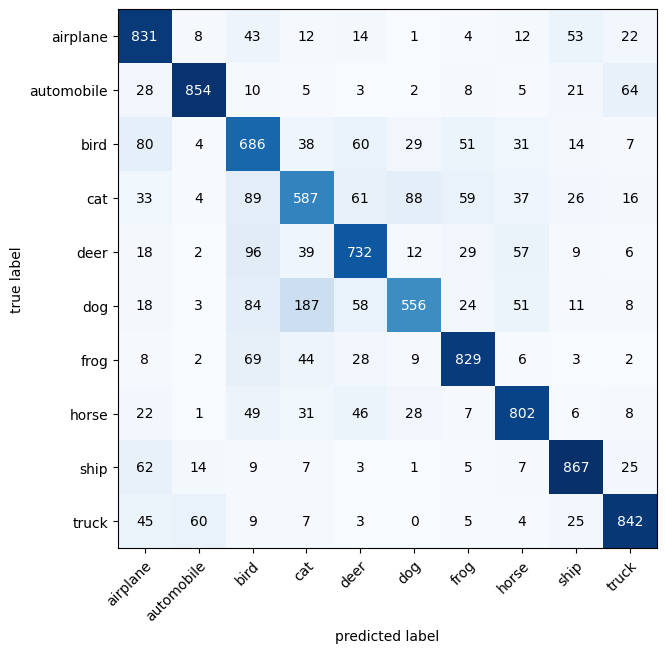

In [37]:
fig,ax = plot_confusion_matrix(
    conf_mat=confmat_tensor.numpy(),     #it works with matplotlib so it likes working with numpy
    class_names=class_names,
    figsize=(10,7)
)

##### We can see that it is confusing the most between cat and dog.
##### Some other notable confusions it is doing are: confusion between automobile and truck, predicting trucks as automobile, and also one more thing to note is the fact that the two lowest blocks along the leading diagonal are of dogs and cats, because they both are being confused for each other the most

In [38]:
import random
random.seed(42)
test_samples = []
test_labels = []

for sample,label in random.sample(list(test_data),k=9):
    test_samples.append(sample)
    test_labels.append(label)

test_samples[0].shape

torch.Size([3, 32, 32])

In [39]:
def make_predictions(model:torch.nn.Module,
                     data:list,
                     device:torch.device=device):
    pred_probs = []
    model.to(device)
    model.eval()
    with torch.inference_mode():
        for sample in data:          # The list contains multiple random images tensor, and their labels, so we loop through each of the image
            sample = torch.unsqueeze(sample,dim=0).to(device)    #We are adding a dimension for batch size, so that we can pass it to the model without shape mismatches

            #Forward pass(model outputs raw logits)
            pred_logit = model(sample)

            #Get prediction probabilitty - We get it using softmax for multiclass 
            pred_prob = torch.softmax(pred_logit.squeeze(),dim=0)

            #Get pred_prob off of the GPU for further calculations(like maybe with matplotlib)
            pred_probs.append(pred_prob.cpu())

    #Stack the pred_probs to turn list into Tensor 
    return torch.stack(pred_probs)

Text(0.5, 1.0, 'truck')

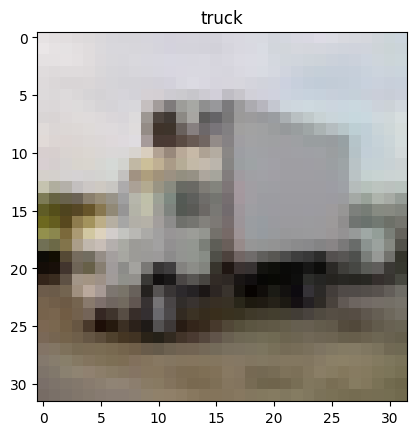

In [40]:
mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(3,1,1)    # I added view to change the shape as without it, I was getting an error for dimension incompatability 
std = torch.tensor([0.2470, 0.2435, 0.2616]).view(3,1,1)     # because before it mean and std were of shape [3], so it was like mutliplying 3 dimensions with 1 dimension, which throwed an error, so added the 1 and 1 to allign

plt.imshow((test_samples[0]*std +mean).permute(1,2,0))
plt.title(class_names[test_labels[0]])

In [41]:
#Make predictions
pred_probs = make_predictions(model=model_3,
                              data=test_samples)

# Converting the pred probabilities to prediction labels and comparing with the test_labels
pred_labels = pred_probs.argmax(dim=1)
print(pred_labels)

tensor([9, 2, 1, 3, 7, 5, 7, 0, 9])


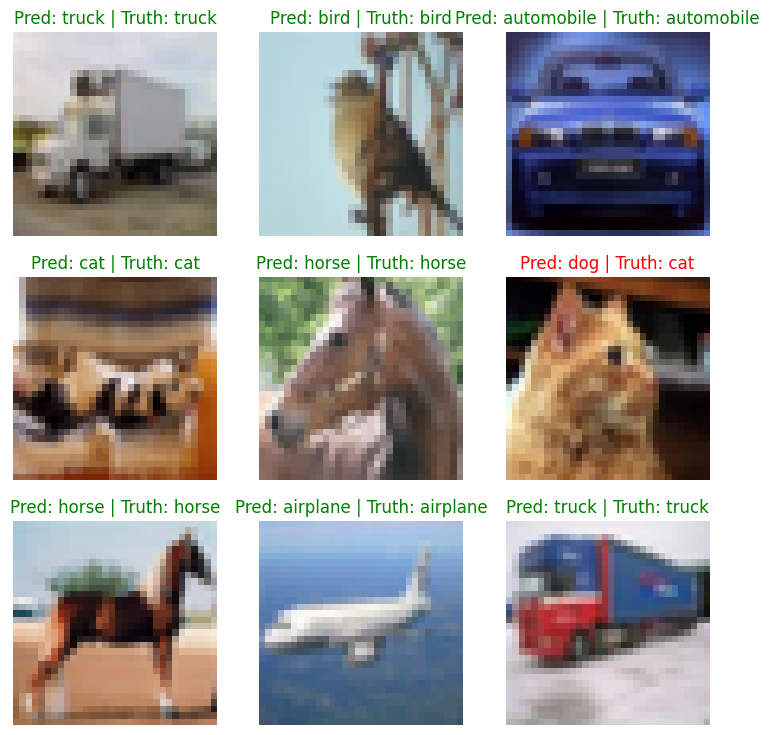

In [42]:
# Plot predictions 
plt.figure(figsize=(9,9))
nrows,ncols=3,3
for i,sample in enumerate(test_samples):
    plt.subplot(nrows,ncols,i+1)

    plt.imshow((sample*std+mean).permute(1,2,0))

    #Get the predicted label
    pred_label = class_names[pred_labels[i]]

    #Get the true label
    true_label = class_names[test_labels[i]]

    #create a title for the plot 
    title_text = f"Pred: {pred_label} | Truth: {true_label}"

    #Check for equality between predicter and truth label along with color coding 
    if pred_label == true_label :
        plt.title(title_text,c='g')   #green text if prediction same
    else:
        plt.title(title_text,c='r')    #red if wrong 

    plt.axis(False)

In [43]:
#### Now I will run the exact same model runs on my CPU to compare the computational speeds:-
device = "cpu"
print(device)

cpu


In [44]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)
model_0_cpu = LinearModel(input_shape = 3*32*32,
                     hidden_units=128,
                     output_shape=len(class_names)).to(device)

loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(params=model_0_cpu.parameters(),
                            lr=0.001)

train_time_start = timer()
epochs = 10
for epoch in range(epochs):
    print(f"Epoch {epoch}\n--------")
    train_step(model=model_0_cpu, data_loader=train_dataloader,optimizer=optimizer,loss_fn=loss_fn,accuracy_fn=accuracy_fn,device=device)

    test_step(model=model_0_cpu,data_loader=test_dataloader,loss_fn=loss_fn,accuracy_fn=accuracy_fn,device=device)

train_time_end = timer()
total_train_time_on_model_0_cpu = print_train_time(start=train_time_start,end=train_time_end,device=device)

Epoch 0
--------
Training Loss: 1.8405 |  Training Accuracy: 35.82%
Testing Loss: 1.7580 |  Testing Accuracy: 38.64%
Epoch 1
--------
Training Loss: 1.7646 |  Training Accuracy: 38.70%
Testing Loss: 1.7636 |  Testing Accuracy: 37.99%
Epoch 2
--------
Training Loss: 1.7379 |  Training Accuracy: 40.20%
Testing Loss: 1.7372 |  Testing Accuracy: 39.13%
Epoch 3
--------
Training Loss: 1.7276 |  Training Accuracy: 40.67%
Testing Loss: 1.7318 |  Testing Accuracy: 40.23%
Epoch 4
--------
Training Loss: 1.7181 |  Training Accuracy: 40.92%
Testing Loss: 1.7450 |  Testing Accuracy: 39.07%
Epoch 5
--------
Training Loss: 1.7108 |  Training Accuracy: 41.09%
Testing Loss: 1.7383 |  Testing Accuracy: 39.45%
Epoch 6
--------
Training Loss: 1.7027 |  Training Accuracy: 41.64%
Testing Loss: 1.7430 |  Testing Accuracy: 39.58%
Epoch 7
--------
Training Loss: 1.6979 |  Training Accuracy: 41.66%
Testing Loss: 1.7435 |  Testing Accuracy: 39.19%
Epoch 8
--------
Training Loss: 1.6918 |  Training Accuracy: 42.

In [45]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)
model_1_cpu = LinearAndNonLinearModel(input_shape=3*32*32,
                                 hidden_units=128,
                                 output_shape=len(class_names)).to(device)

loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(params=model_1_cpu.parameters(),
                            lr=0.001)
train_time_start = timer()
epochs = 10
for epoch in range(epochs):
    print(f"Epoch {epoch}  \n--------")
    train_step(model=model_1_cpu,data_loader=train_dataloader,optimizer=optimizer,loss_fn=loss_fn,accuracy_fn=accuracy_fn,device=device)

    test_step(model=model_1_cpu,data_loader=test_dataloader,loss_fn=loss_fn,accuracy_fn=accuracy_fn,device=device)

train_time_end = timer()
total_train_time_on_model_1_cpu = print_train_time(start=train_time_start,end=train_time_end,device=device)

Epoch 0  
--------
Training Loss: 1.6497 |  Training Accuracy: 41.84%
Testing Loss: 1.5134 |  Testing Accuracy: 46.26%
Epoch 1  
--------
Training Loss: 1.4442 |  Training Accuracy: 49.23%
Testing Loss: 1.4525 |  Testing Accuracy: 48.81%
Epoch 2  
--------
Training Loss: 1.3489 |  Training Accuracy: 52.79%
Testing Loss: 1.3919 |  Testing Accuracy: 50.87%
Epoch 3  
--------
Training Loss: 1.2691 |  Training Accuracy: 55.44%
Testing Loss: 1.3932 |  Testing Accuracy: 51.31%
Epoch 4  
--------
Training Loss: 1.2085 |  Training Accuracy: 57.48%
Testing Loss: 1.3808 |  Testing Accuracy: 51.01%
Epoch 5  
--------
Training Loss: 1.1538 |  Training Accuracy: 59.40%
Testing Loss: 1.3796 |  Testing Accuracy: 51.86%
Epoch 6  
--------
Training Loss: 1.1058 |  Training Accuracy: 61.13%
Testing Loss: 1.4115 |  Testing Accuracy: 51.57%
Epoch 7  
--------
Training Loss: 1.0559 |  Training Accuracy: 62.72%
Testing Loss: 1.4084 |  Testing Accuracy: 52.30%
Epoch 8  
--------
Training Loss: 1.0113 |  Trai

In [46]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

model_2_cpu = CNNModel(input_shape=3,
                  hidden_units=32,
                  output_shape=len(class_names)).to(device)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_2_cpu.parameters(),
                             lr=0.001)
train_time_start_model_2 = timer()
epochs = 10
for epoch in range(epochs):
    print(f"Epoch: {epoch}\n--------")
    train_step(model=model_2_cpu,
               data_loader=train_dataloader,
               loss_fn=loss_fn,
               optimizer=optimizer,
               accuracy_fn=accuracy_fn,
               device = device)

    test_step(model=model_2_cpu,
               data_loader=test_dataloader,
               loss_fn=loss_fn,
               accuracy_fn=accuracy_fn,
               device = device)

train_time_end_model_2 = timer()
total_train_time_on_model_2_cpu = print_train_time(start=train_time_start_model_2,end=train_time_end_model_2,device=device)

Epoch: 0
--------
Training Loss: 1.5934 |  Training Accuracy: 42.34%
Testing Loss: 1.3182 |  Testing Accuracy: 52.16%
Epoch: 1
--------
Training Loss: 1.2285 |  Training Accuracy: 56.31%
Testing Loss: 1.1566 |  Testing Accuracy: 58.77%
Epoch: 2
--------
Training Loss: 1.0679 |  Training Accuracy: 62.51%
Testing Loss: 1.0457 |  Testing Accuracy: 63.24%
Epoch: 3
--------
Training Loss: 0.9637 |  Training Accuracy: 66.52%
Testing Loss: 0.9988 |  Testing Accuracy: 65.00%
Epoch: 4
--------
Training Loss: 0.8880 |  Training Accuracy: 69.20%
Testing Loss: 0.9194 |  Testing Accuracy: 67.87%
Epoch: 5
--------
Training Loss: 0.8292 |  Training Accuracy: 71.22%
Testing Loss: 0.8800 |  Testing Accuracy: 69.35%
Epoch: 6
--------
Training Loss: 0.7843 |  Training Accuracy: 72.89%
Testing Loss: 0.8519 |  Testing Accuracy: 71.06%
Epoch: 7
--------
Training Loss: 0.7427 |  Training Accuracy: 74.22%
Testing Loss: 0.8283 |  Testing Accuracy: 71.27%
Epoch: 8
--------
Training Loss: 0.7136 |  Training Accu

In [47]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

model_3_cpu = CNNModel(input_shape=3,
                  hidden_units=64,    # I am keeping this as 64 hidden units as it was taking way too long to run 128 hidden units
                  output_shape=len(class_names)).to(device)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_3_cpu.parameters(),
                             lr=0.001)
train_time_start_model_3 = timer()
epochs = 10
for epoch in range(epochs):
    print(f"Epoch: {epoch}\n--------")
    train_step(model=model_3_cpu,
               data_loader=train_dataloader,
               loss_fn=loss_fn,
               optimizer=optimizer,
               accuracy_fn=accuracy_fn,
               device = device)

    test_step(model=model_3_cpu,
               data_loader=test_dataloader,
               loss_fn=loss_fn,
               accuracy_fn=accuracy_fn,
               device = device)

train_time_end_model_3 = timer()
total_train_time_on_model_3_cpu = print_train_time(start=train_time_start_model_3,end=train_time_end_model_3,device=device)

Epoch: 0
--------
Training Loss: 1.4916 |  Training Accuracy: 45.85%
Testing Loss: 1.2198 |  Testing Accuracy: 56.22%
Epoch: 1
--------
Training Loss: 1.0602 |  Training Accuracy: 62.76%
Testing Loss: 1.0161 |  Testing Accuracy: 64.98%
Epoch: 2
--------
Training Loss: 0.8795 |  Training Accuracy: 69.32%
Testing Loss: 0.8673 |  Testing Accuracy: 69.93%
Epoch: 3
--------
Training Loss: 0.7763 |  Training Accuracy: 73.18%
Testing Loss: 0.7952 |  Testing Accuracy: 72.07%
Epoch: 4
--------
Training Loss: 0.7044 |  Training Accuracy: 75.52%
Testing Loss: 0.8229 |  Testing Accuracy: 71.71%
Epoch: 5
--------
Training Loss: 0.6548 |  Training Accuracy: 77.25%
Testing Loss: 0.7509 |  Testing Accuracy: 73.70%
Epoch: 6
--------
Training Loss: 0.6132 |  Training Accuracy: 78.85%
Testing Loss: 0.7255 |  Testing Accuracy: 74.87%
Epoch: 7
--------
Training Loss: 0.5663 |  Training Accuracy: 80.20%
Testing Loss: 0.7181 |  Testing Accuracy: 74.92%
Epoch: 8
--------
Training Loss: 0.5342 |  Training Accu

In [48]:
model_0_cpu_results = eval_model(model=model_0_cpu,
                            data_loader=test_dataloader,
                            loss_fn=loss_fn,
                            accuracy_fn=accuracy_fn,
                            device=device)
model_1_cpu_results = eval_model(model=model_1_cpu,
                             data_loader=test_dataloader,
                             loss_fn=loss_fn,
                             accuracy_fn=accuracy_fn,
                             device=device)
model_2_cpu_results = eval_model(model=model_2_cpu,
                             data_loader=test_dataloader,
                             loss_fn=loss_fn,
                             accuracy_fn=accuracy_fn,
                             device=device)
model_3_cpu_results = eval_model(model=model_3_cpu,
                             data_loader=test_dataloader,
                             loss_fn=loss_fn,
                             accuracy_fn=accuracy_fn,
                             device=device)
print(model_0_cpu_results)
print(model_1_cpu_results)
print(model_2_cpu_results)
print(model_3_cpu_results)

{'model_name': 'LinearModel', 'model_loss': 1.7381385564804077, 'model_acc': 39.40862341772152}
{'model_name': 'LinearAndNonLinearModel', 'model_loss': 1.445522427558899, 'model_acc': 51.58227848101266}
{'model_name': 'CNNModel', 'model_loss': 0.7861108183860779, 'model_acc': 73.04193037974683}
{'model_name': 'CNNModel', 'model_loss': 0.7538869380950928, 'model_acc': 74.57476265822785}


In [49]:
cpu_model_results = pd.DataFrame([model_0_cpu_results,model_1_cpu_results,model_2_cpu_results,model_3_cpu_results])
model_results = pd.concat([model_results,cpu_model_results],ignore_index=True)
print(model_results)

                model_name  model_loss  model_acc  Training Time
0              LinearModel    1.738139  39.408623      88.593778
1  LinearAndNonLinearModel    1.424085  52.145965      89.229650
2                 CNNModel    0.832001  71.400316      85.638157
3                 CNNModel    0.943436  75.504351     108.238714
4              LinearModel    1.738139  39.408623            NaN
5  LinearAndNonLinearModel    1.445522  51.582278            NaN
6                 CNNModel    0.786111  73.041930            NaN
7                 CNNModel    0.753887  74.574763            NaN


In [50]:
model_results.loc[4:7,"Training Time"] = [total_train_time_on_model_0_cpu,total_train_time_on_model_1_cpu,total_train_time_on_model_2_cpu,total_train_time_on_model_3_cpu]

In [51]:
print(model_results)

                model_name  model_loss  model_acc  Training Time
0              LinearModel    1.738139  39.408623      88.593778
1  LinearAndNonLinearModel    1.424085  52.145965      89.229650
2                 CNNModel    0.832001  71.400316      85.638157
3                 CNNModel    0.943436  75.504351     108.238714
4              LinearModel    1.738139  39.408623      89.712001
5  LinearAndNonLinearModel    1.445522  51.582278      84.046456
6                 CNNModel    0.786111  73.041930     636.573539
7                 CNNModel    0.753887  74.574763    1987.956193


#### Since the accuracies are almost the same, so the confusion matrix and graphs would come out as same

In [52]:
fig.savefig("Plot_images/confusion_matrix.png",
            dpi=300,
            bbox_inches="tight")

In [53]:

MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True,exist_ok=True)

MODEL_NAME = "CNN_64_GPU.pth"
MODEL_SAVE_PATH = MODEL_PATH/MODEL_NAME
torch.save(obj = model_3.state_dict(),f=MODEL_SAVE_PATH) 

#### Saving the model's parameters, so that they can be loaded in different programs and used

#### Okay so We achieved a peak accuracy of 76 percent with our CNN model. Now my next steps includes applying data augmentation, to create artifical dataset so that the model actually tries to learn the patterns, and to prevent overfitting, that is the model just learns the training data and not learn the underlying shapes, we will use Batch Normalization and Dropout.
##### 1] Batch Normalization :- It normalizes the activations of the neurons of each mini batches, so they have zero mean and a variance value of 1. We do this because if we don't normalize the activations, then the deeper layers of neurons would constantly have to adjust and deal accordingly to the big changes made in the initial layer, so they would never really be able to learn the patterns the best that they can 
##### 2] Dropout :- It randomly deactivates some neurons, so that the other neurons don't overpower this neuron, and each neuron kind of thinks for itself and tries to learn the patterns, rather than depending on onee or two major neurons. So it helps prevent overfitting
##### 3] However in common practice, we just use BatchNorm as using BatchNorm and Dropout together can cause issues.
##### 4] And we will be using different combinations of data augmentations like RandomHorizontalFlip(),RandomCrop(),ColourJitter(),TrivialAugmentWide(),CutMix,MixUp,RandAugment,RandomErasing() to see how does it affect the accuracy

In [54]:
# First we need to update our CNN model, to include BatchNorm in the Convolution layers
class AugCNNModel(nn.Module):
    def __init__(self,
                 input_shape:int,
                 hidden_units:int,
                 output_shape:int):
        super().__init__()
        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(in_channels=input_shape,out_channels=hidden_units,kernel_size=3,padding=0,stride=1),
            nn.BatchNorm2d(num_features=hidden_units),
            nn.ReLU(),
            nn.Conv2d(in_channels = hidden_units, out_channels=hidden_units,kernel_size=3,padding=0,stride=1),
            nn.BatchNorm2d(num_features=hidden_units),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(in_channels=hidden_units,out_channels=hidden_units,kernel_size=3,padding=0,stride=1),
            nn.BatchNorm2d(num_features=hidden_units),
            nn.ReLU(),
            nn.Conv2d(in_channels = hidden_units, out_channels=hidden_units,kernel_size=3,padding=0,stride=1),
            nn.BatchNorm2d(num_features=hidden_units),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=hidden_units*5*5,   #We will calculate this later by using a dummy variable
                     out_features=output_shape)
        )
    def forward(self,x):
        x = self.conv_block_1(x)
        x=self.conv_block_2(x)
        x= self.classifier(x)
        return x

In [55]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


In [56]:
aug_model_0 = AugCNNModel(input_shape=3,hidden_units=128,output_shape=len(class_names)).to(device)
print(aug_model_0)

AugCNNModel(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 128, kernel_size=(3, 3), stride=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1))
    (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1))
    (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear

In [57]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=aug_model_0.parameters(), lr =0.001)

In [58]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

epochs = 10                 

train_time_start_aug_model_0 = timer()
for epoch in range(epochs):
    print(f"Epoch: {epoch}\n--------")
    train_step(model=aug_model_0,
              data_loader = train_dataloader,
              optimizer=optimizer,
              loss_fn=loss_fn,
              accuracy_fn=accuracy_fn)
    test_step(model=aug_model_0,
             data_loader=test_dataloader,
             loss_fn=loss_fn,
             accuracy_fn=accuracy_fn)

train_time_end_aug_model_0 = timer()
total_train_time_aug_model_0 = print_train_time(start=train_time_start_aug_model_0,end=train_time_end_aug_model_0,device=device)

Epoch: 0
--------
Training Loss: 1.2047 |  Training Accuracy: 57.08%
Testing Loss: 0.8985 |  Testing Accuracy: 68.86%
Epoch: 1
--------
Training Loss: 0.7882 |  Training Accuracy: 72.65%
Testing Loss: 0.7819 |  Testing Accuracy: 73.10%
Epoch: 2
--------
Training Loss: 0.6411 |  Training Accuracy: 77.94%
Testing Loss: 0.7437 |  Testing Accuracy: 74.35%
Epoch: 3
--------
Training Loss: 0.5334 |  Training Accuracy: 81.52%
Testing Loss: 0.7258 |  Testing Accuracy: 76.24%
Epoch: 4
--------
Training Loss: 0.4633 |  Training Accuracy: 83.98%
Testing Loss: 0.6665 |  Testing Accuracy: 77.56%
Epoch: 5
--------
Training Loss: 0.3926 |  Training Accuracy: 86.28%
Testing Loss: 0.6417 |  Testing Accuracy: 78.49%
Epoch: 6
--------
Training Loss: 0.3276 |  Training Accuracy: 88.86%
Testing Loss: 0.6144 |  Testing Accuracy: 79.92%
Epoch: 7
--------
Training Loss: 0.2748 |  Training Accuracy: 90.50%
Testing Loss: 0.6448 |  Testing Accuracy: 79.51%
Epoch: 8
--------
Training Loss: 0.2200 |  Training Accu

##### Okay so this is still definitely showing signs of overfitting, so let's add a dropout layer and see whether it improves or not

In [59]:
# First we need to update our CNN model, to include BatchNorm in the Convolution layers
class AugCNNModel(nn.Module):
    def __init__(self,
                 input_shape:int,
                 hidden_units:int,
                 output_shape:int):
        super().__init__()
        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(in_channels=input_shape,out_channels=hidden_units,kernel_size=3,padding=0,stride=1),
            nn.BatchNorm2d(num_features=hidden_units),
            nn.ReLU(),
            nn.Conv2d(in_channels = hidden_units, out_channels=hidden_units,kernel_size=3,padding=0,stride=1),
            nn.BatchNorm2d(num_features=hidden_units),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(in_channels=hidden_units,out_channels=hidden_units,kernel_size=3,padding=0,stride=1),
            nn.BatchNorm2d(num_features=hidden_units),
            nn.ReLU(),
            nn.Conv2d(in_channels = hidden_units, out_channels=hidden_units,kernel_size=3,padding=0,stride=1),
            nn.BatchNorm2d(num_features=hidden_units),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=0.2),
            nn.Linear(in_features=hidden_units*5*5,   #We will calculate this later by using a dummy variable
                     out_features=output_shape)
        )
    def forward(self,x):
        x = self.conv_block_1(x)
        x=self.conv_block_2(x)
        x= self.classifier(x)
        return x

In [60]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

aug_model_1 = AugCNNModel(input_shape=3,hidden_units=64,output_shape=len(class_names)).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=aug_model_1.parameters(), lr =0.001)

epochs = 10         

train_time_start_aug_model_1 = timer()
for epoch in range(epochs):
    print(f"Epoch: {epoch}\n--------")
    train_step(model=aug_model_1,
              data_loader = train_dataloader,
              optimizer=optimizer,
              loss_fn=loss_fn,
              accuracy_fn=accuracy_fn)
    test_step(model=aug_model_1,
             data_loader=test_dataloader,
             loss_fn=loss_fn,
             accuracy_fn=accuracy_fn)

train_time_end_aug_model_1 = timer()
total_train_time_aug_model_1 = print_train_time(start=train_time_start_aug_model_1,end=train_time_end_aug_model_1,device=device)

Epoch: 0
--------
Training Loss: 1.2364 |  Training Accuracy: 55.67%
Testing Loss: 1.0277 |  Testing Accuracy: 63.36%
Epoch: 1
--------
Training Loss: 0.8629 |  Training Accuracy: 69.79%
Testing Loss: 0.8754 |  Testing Accuracy: 70.32%
Epoch: 2
--------
Training Loss: 0.7431 |  Training Accuracy: 73.85%
Testing Loss: 0.7450 |  Testing Accuracy: 74.00%
Epoch: 3
--------
Training Loss: 0.6692 |  Training Accuracy: 76.67%
Testing Loss: 0.8493 |  Testing Accuracy: 71.21%
Epoch: 4
--------
Training Loss: 0.6067 |  Training Accuracy: 78.85%
Testing Loss: 0.7255 |  Testing Accuracy: 75.19%
Epoch: 5
--------
Training Loss: 0.5607 |  Training Accuracy: 80.63%
Testing Loss: 0.6313 |  Testing Accuracy: 78.47%
Epoch: 6
--------
Training Loss: 0.5201 |  Training Accuracy: 81.98%
Testing Loss: 0.6703 |  Testing Accuracy: 77.73%
Epoch: 7
--------
Training Loss: 0.4835 |  Training Accuracy: 83.18%
Testing Loss: 0.7305 |  Testing Accuracy: 75.46%
Epoch: 8
--------
Training Loss: 0.4520 |  Training Accu

##### Alright, so the dropout and BatchNorm did help us to reduce overfitting
##### Now let's move on to data augmentation, and see whether it imrpoves our models. Data Augmentation is the process of artificially changing the data, so the training examples have more variations and the model can learn different variations
##### I try the RandomHorizontalFlip, which randomly flips an image based on the probability given as argument, so it rotates the image by 180 degree horizontally. I also added RandomCrop, which randomly crops out some section of the image, according to the specified size passed as the argument, and I made sure that the final cropped image is the same as the initial size, using padding which adds pixels to the left, right, top and bottom of the image. I am also going to try ColorJitter() which changes the intensity, colour grading, contrast and hue, and I will select the best combination out of those

In [61]:
train_transform = v2.Compose([v2.ToImage(),
                            v2.RandomHorizontalFlip(),
                            v2.RandomCrop(size=32,padding=4),
                            #v2.ColorJitter(brightness=0.2,contrast=0.2,saturation=0.2,hue=0.1),
                            v2.ToDtype(dtype=torch.float,scale=True),
                            v2.Normalize(mean=[0.4914,0.4822,0.4465],std=[0.2470,0.2435,0.2616])])
train_data.transform = train_transform

In [62]:
test_transform = v2.Compose([v2.ToImage(),
                             v2.ToDtype(dtype=torch.float,scale=True),
                             v2.Normalize(mean=[0.4914,0.4822,0.4465],std=[0.2470,0.2435,0.2616])])
test_data.transform = test_transform

In [63]:
train_dataloader = DataLoader(dataset=train_data,batch_size= BATCH_SIZE, shuffle=True,num_workers=2,pin_memory=True,persistent_workers=True)
test_dataloader = DataLoader(dataset=test_data,batch_size=BATCH_SIZE,shuffle=False,num_workers=2,pin_memory=True,persistent_workers=True)

In [64]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

aug_model_2 = AugCNNModel(input_shape=3,hidden_units=256,output_shape=len(class_names)).to(device)   #I also tested different number of hidden units, as before the model was overfitting which is also caused by large numbers of hidden_units, but since now we added data augmentation and BatchNorm and Dropout, we're trying to increase accuracy and prevent overfitting so I changed and found 256 to be the best
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=aug_model_2.parameters(), lr =0.001)

epochs = 25         #Increasing the epochs, as it will help our model learn the patterns better as I have also added data augmentations now

train_time_start_aug_model_2 = timer()
for epoch in range(epochs):
    print(f"Epoch: {epoch}\n--------")
    train_step(model=aug_model_2,
              data_loader = train_dataloader,
              optimizer=optimizer,
              loss_fn=loss_fn,
              accuracy_fn=accuracy_fn)
    test_step(model=aug_model_2,
             data_loader=test_dataloader,
             loss_fn=loss_fn,
             accuracy_fn=accuracy_fn)

train_time_end_aug_model_2 = timer()
total_train_time_aug_model_2 = print_train_time(start=train_time_start_aug_model_2,end=train_time_end_aug_model_2,device=device)

Epoch: 0
--------
Training Loss: 1.5124 |  Training Accuracy: 46.13%
Testing Loss: 1.2486 |  Testing Accuracy: 55.48%
Epoch: 1
--------
Training Loss: 1.0646 |  Training Accuracy: 62.69%
Testing Loss: 0.8367 |  Testing Accuracy: 70.58%
Epoch: 2
--------
Training Loss: 0.8847 |  Training Accuracy: 68.90%
Testing Loss: 0.7472 |  Testing Accuracy: 74.04%
Epoch: 3
--------
Training Loss: 0.7871 |  Training Accuracy: 72.79%
Testing Loss: 0.8150 |  Testing Accuracy: 72.45%
Epoch: 4
--------
Training Loss: 0.7183 |  Training Accuracy: 75.07%
Testing Loss: 0.6674 |  Testing Accuracy: 77.24%
Epoch: 5
--------
Training Loss: 0.6546 |  Training Accuracy: 77.46%
Testing Loss: 0.7034 |  Testing Accuracy: 75.84%
Epoch: 6
--------
Training Loss: 0.5992 |  Training Accuracy: 79.07%
Testing Loss: 0.5840 |  Testing Accuracy: 80.27%
Epoch: 7
--------
Training Loss: 0.5627 |  Training Accuracy: 80.76%
Testing Loss: 0.6064 |  Testing Accuracy: 80.51%
Epoch: 8
--------
Training Loss: 0.5215 |  Training Accu

##### Okay so increasing the epochs and hidden units did help us as we achieved a best test accuracy of 88.47 percent and the lowest loss, which corresponded to the highest test accuracy was 0.3984. I had also run the experiment with colour jitter and it reached a peak test accuracy of 85ish percent so the best combination for now is RandomHorizontalFlip and RandomCrop.
##### Now for next data augmentation techniques, I came accross the following article: https://pytorch.org/blog/how-to-train-state-of-the-art-models-using-torchvision-latest-primitives/
##### and I have decided to use RandomErasing, MixUp, CutMix, and also before these I also wanted to try out TrivialAugmentWide, which randomly applies augmentations and randomly sets the magnitude of those augmentations

In [65]:
train_transform = v2.Compose([v2.ToImage(),
                            v2.TrivialAugmentWide(),
                            v2.ToDtype(dtype=torch.float,scale=True),
                            v2.Normalize(mean=[0.4914,0.4822,0.4465],std=[0.2470,0.2435,0.2616])])
train_data.transform = train_transform
train_dataloader = DataLoader(dataset=train_data,batch_size= BATCH_SIZE, shuffle=True,num_workers=2,pin_memory=True,persistent_workers=True)

In [66]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

aug_model_2 = AugCNNModel(input_shape=3,hidden_units=256,output_shape=len(class_names)).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=aug_model_2.parameters(), lr =0.001)

epochs = 25         

train_time_start_aug_model_2 = timer()
for epoch in range(epochs):
    print(f"Epoch: {epoch}\n--------")
    train_step(model=aug_model_2,
              data_loader = train_dataloader,
              optimizer=optimizer,
              loss_fn=loss_fn,
              accuracy_fn=accuracy_fn)
    test_step(model=aug_model_2,
             data_loader=test_dataloader,
             loss_fn=loss_fn,
             accuracy_fn=accuracy_fn)

train_time_end_aug_model_2 = timer()
total_train_time_aug_model_2 = print_train_time(start=train_time_start_aug_model_2,end=train_time_end_aug_model_2,device=device)

Epoch: 0
--------
Training Loss: 1.8017 |  Training Accuracy: 35.92%
Testing Loss: 1.2059 |  Testing Accuracy: 58.04%
Epoch: 1
--------
Training Loss: 1.4210 |  Training Accuracy: 49.75%
Testing Loss: 0.9668 |  Testing Accuracy: 65.74%
Epoch: 2
--------
Training Loss: 1.2573 |  Training Accuracy: 55.78%
Testing Loss: 0.8441 |  Testing Accuracy: 70.17%
Epoch: 3
--------
Training Loss: 1.1601 |  Training Accuracy: 59.38%
Testing Loss: 0.7500 |  Testing Accuracy: 73.67%
Epoch: 4
--------
Training Loss: 1.0749 |  Training Accuracy: 62.09%
Testing Loss: 0.6965 |  Testing Accuracy: 75.64%
Epoch: 5
--------
Training Loss: 1.0183 |  Training Accuracy: 64.01%
Testing Loss: 0.6584 |  Testing Accuracy: 77.41%
Epoch: 6
--------
Training Loss: 0.9728 |  Training Accuracy: 66.01%
Testing Loss: 0.6351 |  Testing Accuracy: 77.68%
Epoch: 7
--------
Training Loss: 0.9253 |  Training Accuracy: 67.39%
Testing Loss: 0.5758 |  Testing Accuracy: 79.39%
Epoch: 8
--------
Training Loss: 0.8882 |  Training Accu

#### So the trivial augment wide did not perform as good as my RandomCrop and RandomHorizontalFlip combination, so I will keep those two as my best augmentations for now.
#### Now I wanted to try the RandomErasing, which randomly erases pixels from a rectangular portion of the image with a given probability whether the Erasing will happen or not . It helps reduce overfitting as the model actually tries to learn the patterns of the pixels and not the position

In [67]:
train_transform = v2.Compose([v2.ToImage(),
                            v2.RandomHorizontalFlip(),
                            v2.RandomCrop(size=32,padding=4),
                            v2.ToDtype(dtype=torch.float,scale=True),
                            v2.RandomErasing(p=0.3),
                            v2.Normalize(mean=[0.4914,0.4822,0.4465],std=[0.2470,0.2435,0.2616])])
train_data.transform = train_transform
train_dataloader = DataLoader(dataset=train_data,batch_size= BATCH_SIZE, shuffle=True,num_workers=2,pin_memory=True,persistent_workers=True)

In [68]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

aug_model_2 = AugCNNModel(input_shape=3,hidden_units=256,output_shape=len(class_names)).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=aug_model_2.parameters(), lr =0.001)

epochs = 25                

train_time_start_aug_model_2 = timer()
for epoch in range(epochs):
    print(f"Epoch: {epoch}\n--------")
    train_step(model=aug_model_2,
              data_loader = train_dataloader,
              optimizer=optimizer,
              loss_fn=loss_fn,
              accuracy_fn=accuracy_fn)
    test_step(model=aug_model_2,
             data_loader=test_dataloader,
             loss_fn=loss_fn,
             accuracy_fn=accuracy_fn)

train_time_end_aug_model_2 = timer()
total_train_time_aug_model_2 = print_train_time(start=train_time_start_aug_model_2,end=train_time_end_aug_model_2,device=device)

Epoch: 0
--------
Training Loss: 1.6096 |  Training Accuracy: 42.53%
Testing Loss: 1.2463 |  Testing Accuracy: 56.37%
Epoch: 1
--------
Training Loss: 1.1722 |  Training Accuracy: 58.34%
Testing Loss: 0.9879 |  Testing Accuracy: 65.57%
Epoch: 2
--------
Training Loss: 1.0030 |  Training Accuracy: 65.08%
Testing Loss: 0.8290 |  Testing Accuracy: 70.21%
Epoch: 3
--------
Training Loss: 0.9019 |  Training Accuracy: 68.39%
Testing Loss: 0.7030 |  Testing Accuracy: 75.24%
Epoch: 4
--------
Training Loss: 0.8284 |  Training Accuracy: 71.23%
Testing Loss: 0.7023 |  Testing Accuracy: 75.51%
Epoch: 5
--------
Training Loss: 0.7732 |  Training Accuracy: 73.35%
Testing Loss: 0.6409 |  Testing Accuracy: 77.79%
Epoch: 6
--------
Training Loss: 0.7232 |  Training Accuracy: 74.87%
Testing Loss: 0.6029 |  Testing Accuracy: 79.08%
Epoch: 7
--------
Training Loss: 0.6757 |  Training Accuracy: 76.56%
Testing Loss: 0.6145 |  Testing Accuracy: 78.73%
Epoch: 8
--------
Training Loss: 0.6435 |  Training Accu

#### Adding RandomErasing has an increase in accuracy and reduction in loss with 87.84 percent accuracy and 0.3715 loss, so the best combination that I got is: RandomHorizontalFlip(),RandomCrop() and RandomErasing()

#### Let's now try the CutMix, wherein one rectangual patch is cut from one training image and it is pasted on top of another training image, and the truth labels are mixed proportionally to the area of the base image and the image that is pasted on top 

In [69]:
def train_step(model:torch.nn.Module,
              data_loader:torch.utils.data.DataLoader,
              optimizer: torch.optim.Optimizer,
              loss_fn:torch.nn.Module,
              accuracy_fn,
              device:torch.device = device):

    train_loss,train_acc = 0,0
    cutmix = v2.CutMix(num_classes=10)
    model.train()
    for batch, (X,y) in enumerate(data_loader):
        X,y = X.to(device,non_blocking=True),y.to(device,non_blocking=True)
        #Applying cutmix
        X,y = cutmix(X,y)
        #1 Forward pass
        y_pred = model(X)

        #2 Calculate loss and accuracy 
        loss = loss_fn(y_pred,y)
        train_loss+=loss.item()     #This I realised later, when I studied more, is that we should use .item(), as it converts the final single values tensor to a python datatype, so it helps fasten our code, as if we don't do this then train_loss would remember history of each batch, and it would continue on to the next batches. However, we make sure not to do the .item() directly in the above step, as we want the loss variable to know the past history for backpropogation(loss.backward) to work, but dont need the history for loss calculation
        train_acc += accuracy_fn(y_true = y.argmax(dim=1), y_pred=y_pred.argmax(dim=1))   #argmax because we wan't the labels, not the probabilities

        #3 Optimizer zero grad
        optimizer.zero_grad()

        #4. Loss backwards(backpropogation)
        loss.backward()

        #5. Optimizer step(Gradient Descent)
        optimizer.step()

    train_loss /= len(data_loader)    #calculating the metrics per batch
    train_acc /= len(data_loader)

    print(f"Training Loss: {train_loss:.4f} |  Training Accuracy: {train_acc:.2f}%") 

In [70]:
train_transform = v2.Compose([v2.ToImage(),
                            v2.RandomHorizontalFlip(),
                            v2.RandomCrop(size=32,padding=4),
                            v2.ToDtype(dtype=torch.float,scale=True),
                            v2.RandomErasing(p=0.3),
                            v2.Normalize(mean=[0.4914,0.4822,0.4465],std=[0.2470,0.2435,0.2616])])
train_data.transform = train_transform
train_dataloader = DataLoader(dataset=train_data,batch_size= BATCH_SIZE, shuffle=True,num_workers=2,pin_memory=True,persistent_workers=True)

In [71]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

aug_model_2 = AugCNNModel(input_shape=3,hidden_units=256,output_shape=len(class_names)).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=aug_model_2.parameters(), lr =0.001)

epochs = 25     

train_time_start_aug_model_2 = timer()
for epoch in range(epochs):
    print(f"Epoch: {epoch}\n--------")
    train_step(model=aug_model_2,
              data_loader = train_dataloader,
              optimizer=optimizer,
              loss_fn=loss_fn,
              accuracy_fn=accuracy_fn)
    test_step(model=aug_model_2,
             data_loader=test_dataloader,
             loss_fn=loss_fn,
             accuracy_fn=accuracy_fn)

train_time_end_aug_model_2 = timer()
total_train_time_aug_model_2 = print_train_time(start=train_time_start_aug_model_2,end=train_time_end_aug_model_2,device=device)

Epoch: 0
--------
Training Loss: 2.0552 |  Training Accuracy: 29.85%
Testing Loss: 1.4667 |  Testing Accuracy: 46.04%
Epoch: 1
--------
Training Loss: 1.8247 |  Training Accuracy: 40.87%
Testing Loss: 1.1089 |  Testing Accuracy: 62.89%
Epoch: 2
--------
Training Loss: 1.7249 |  Training Accuracy: 45.42%
Testing Loss: 1.0774 |  Testing Accuracy: 62.52%
Epoch: 3
--------
Training Loss: 1.6581 |  Training Accuracy: 49.59%
Testing Loss: 1.0675 |  Testing Accuracy: 62.98%
Epoch: 4
--------
Training Loss: 1.6270 |  Training Accuracy: 51.00%
Testing Loss: 0.9345 |  Testing Accuracy: 68.15%
Epoch: 5
--------
Training Loss: 1.5675 |  Training Accuracy: 54.18%
Testing Loss: 0.9093 |  Testing Accuracy: 69.46%
Epoch: 6
--------
Training Loss: 1.5546 |  Training Accuracy: 55.83%
Testing Loss: 0.8252 |  Testing Accuracy: 72.17%
Epoch: 7
--------
Training Loss: 1.5383 |  Training Accuracy: 55.93%
Testing Loss: 0.8334 |  Testing Accuracy: 73.78%
Epoch: 8
--------
Training Loss: 1.4906 |  Training Accu

##### Okay well, cutmix seems to have reduced the testing accuracy, I have tried mutliple augmentation combinations but all peaked out just shy of 86 percent accuracy or less than that. Also the model isnt able to learn that well either, the training accuracy is also less.

##### Let's try MixUp now, which converts the pixel of an image, as a weighted average of two corresponding pixels from two training images,and the labels are matches accordingly
##### and after that we will combine MixUp and CutMix together and see the results, whether they are worth keeping or not

In [72]:
def train_step(model:torch.nn.Module,
              data_loader:torch.utils.data.DataLoader,
              optimizer: torch.optim.Optimizer,
              loss_fn:torch.nn.Module,
              accuracy_fn,
              device:torch.device = device):

    train_loss,train_acc = 0,0
    mixup = v2.MixUp(num_classes=10)
    model.train()
    for batch, (X,y) in enumerate(data_loader):
        X,y = X.to(device,non_blocking=True),y.to(device,non_blocking=True)
        #Applying mixup
        X,y = mixup(X,y)
        #1 Forward pass
        y_pred = model(X)

        #2 Calculate loss and accuracy 
        loss = loss_fn(y_pred,y)
        train_loss+=loss.item()     #This I realised later, when I studied more, is that we should use .item(), as it converts the final single values tensor to a python datatype, so it helps fasten our code, as if we don't do this then train_loss would remember history of each batch, and it would continue on to the next batches. However, we make sure not to do the .item() directly in the above step, as we want the loss variable to know the past history for backpropogation(loss.backward) to work, but dont need the history for loss calculation
        train_acc += accuracy_fn(y_true = y.argmax(dim=1), y_pred=y_pred.argmax(dim=1))   #argmax because we wan't the labels, not the probabilities

        #3 Optimizer zero grad
        optimizer.zero_grad()

        #4. Loss backwards(backpropogation)
        loss.backward()

        #5. Optimizer step(Gradient Descent)
        optimizer.step()

    train_loss /= len(data_loader)    #calculating the metrics per batch
    train_acc /= len(data_loader)

    print(f"Training Loss: {train_loss:.4f} |  Training Accuracy: {train_acc:.2f}%") 

In [73]:
train_transform = v2.Compose([v2.ToImage(),
                            v2.RandomHorizontalFlip(),
                            v2.RandomCrop(size=32,padding=4),
                            v2.ToDtype(dtype=torch.float,scale=True),
                            v2.RandomErasing(p=0.3),
                            v2.Normalize(mean=[0.4914,0.4822,0.4465],std=[0.2470,0.2435,0.2616])])
train_data.transform = train_transform
train_dataloader = DataLoader(dataset=train_data,batch_size= BATCH_SIZE, shuffle=True,num_workers=2,pin_memory=True,persistent_workers=True)

In [74]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

aug_model_2 = AugCNNModel(input_shape=3,hidden_units=256,output_shape=len(class_names)).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=aug_model_2.parameters(), lr =0.001)

epochs = 25         

train_time_start_aug_model_2 = timer()
for epoch in range(epochs):
    print(f"Epoch: {epoch}\n--------")
    train_step(model=aug_model_2,
              data_loader = train_dataloader,
              optimizer=optimizer,
              loss_fn=loss_fn,
              accuracy_fn=accuracy_fn)
    test_step(model=aug_model_2,
             data_loader=test_dataloader,
             loss_fn=loss_fn,
             accuracy_fn=accuracy_fn)

train_time_end_aug_model_2 = timer()
total_train_time_aug_model_2 = print_train_time(start=train_time_start_aug_model_2,end=train_time_end_aug_model_2,device=device)

Epoch: 0
--------
Training Loss: 2.0209 |  Training Accuracy: 32.69%
Testing Loss: 1.5016 |  Testing Accuracy: 47.05%
Epoch: 1
--------
Training Loss: 1.7488 |  Training Accuracy: 46.32%
Testing Loss: 1.1266 |  Testing Accuracy: 61.58%
Epoch: 2
--------
Training Loss: 1.6736 |  Training Accuracy: 51.47%
Testing Loss: 1.0018 |  Testing Accuracy: 67.05%
Epoch: 3
--------
Training Loss: 1.5998 |  Training Accuracy: 55.24%
Testing Loss: 0.9539 |  Testing Accuracy: 67.93%
Epoch: 4
--------
Training Loss: 1.5119 |  Training Accuracy: 58.98%
Testing Loss: 0.8626 |  Testing Accuracy: 71.91%
Epoch: 5
--------
Training Loss: 1.5039 |  Training Accuracy: 61.35%
Testing Loss: 0.7973 |  Testing Accuracy: 75.63%
Epoch: 6
--------
Training Loss: 1.4529 |  Training Accuracy: 63.07%
Testing Loss: 0.8122 |  Testing Accuracy: 74.16%
Epoch: 7
--------
Training Loss: 1.4432 |  Training Accuracy: 63.92%
Testing Loss: 0.8251 |  Testing Accuracy: 74.22%
Epoch: 8
--------
Training Loss: 1.4246 |  Training Accu

##### MixUp performed worse than CutMix as it has both high loss and lower accuracy value. I will lastly see if CutMix and MixUp together can perform better else I will remove them 

In [75]:
def train_step(model:torch.nn.Module,
              data_loader:torch.utils.data.DataLoader,
              optimizer: torch.optim.Optimizer,
              loss_fn:torch.nn.Module,
              accuracy_fn,
              device:torch.device = device):

    train_loss,train_acc = 0,0
    mixup = v2.MixUp(num_classes=10)
    cutmix = v2.CutMix(num_classes=10)
    model.train()
    for batch, (X,y) in enumerate(data_loader):
        X,y = X.to(device,non_blocking=True),y.to(device,non_blocking=True)
        #Applying cutmix and mixup
        X,y = cutmix(X,y)
        X,y = mixup(X,y)
        #1 Forward pass
        y_pred = model(X)

        #2 Calculate loss and accuracy 
        loss = loss_fn(y_pred,y)
        train_loss+=loss.item()     #This I realised later, when I studied more, is that we should use .item(), as it converts the final single values tensor to a python datatype, so it helps fasten our code, as if we don't do this then train_loss would remember history of each batch, and it would continue on to the next batches. However, we make sure not to do the .item() directly in the above step, as we want the loss variable to know the past history for backpropogation(loss.backward) to work, but dont need the history for loss calculation
        train_acc += accuracy_fn(y_true = y.argmax(dim=1), y_pred=y_pred.argmax(dim=1))   #argmax because we wan't the labels, not the probabilities

        #3 Optimizer zero grad
        optimizer.zero_grad()

        #4. Loss backwards(backpropogation)
        loss.backward()

        #5. Optimizer step(Gradient Descent)
        optimizer.step()

    train_loss /= len(data_loader)    #calculating the metrics per batch
    train_acc /= len(data_loader)

    print(f"Training Loss: {train_loss:.4f} |  Training Accuracy: {train_acc:.2f}%") 

In [76]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

aug_model_2 = AugCNNModel(input_shape=3,hidden_units=256,output_shape=len(class_names)).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=aug_model_2.parameters(), lr =0.001)

epochs = 25         

train_time_start_aug_model_2 = timer()
for epoch in range(epochs):
    print(f"Epoch: {epoch}\n--------")
    train_step(model=aug_model_2,
              data_loader = train_dataloader,
              optimizer=optimizer,
              loss_fn=loss_fn,
              accuracy_fn=accuracy_fn)
    test_step(model=aug_model_2,
             data_loader=test_dataloader,
             loss_fn=loss_fn,
             accuracy_fn=accuracy_fn)

train_time_end_aug_model_2 = timer()
total_train_time_aug_model_2 = print_train_time(start=train_time_start_aug_model_2,end=train_time_end_aug_model_2,device=device)

Epoch: 0
--------
Training Loss: 2.1704 |  Training Accuracy: 26.01%
Testing Loss: 1.5274 |  Testing Accuracy: 47.91%
Epoch: 1
--------
Training Loss: 1.9898 |  Training Accuracy: 35.80%
Testing Loss: 1.2556 |  Testing Accuracy: 58.07%
Epoch: 2
--------
Training Loss: 1.9241 |  Training Accuracy: 40.60%
Testing Loss: 1.1842 |  Testing Accuracy: 61.22%
Epoch: 3
--------
Training Loss: 1.8744 |  Training Accuracy: 43.96%
Testing Loss: 1.2207 |  Testing Accuracy: 58.32%
Epoch: 4
--------
Training Loss: 1.8609 |  Training Accuracy: 45.04%
Testing Loss: 1.1497 |  Testing Accuracy: 64.09%
Epoch: 5
--------
Training Loss: 1.8397 |  Training Accuracy: 46.72%
Testing Loss: 1.0300 |  Testing Accuracy: 68.50%
Epoch: 6
--------
Training Loss: 1.8154 |  Training Accuracy: 48.30%
Testing Loss: 0.9965 |  Testing Accuracy: 67.06%
Epoch: 7
--------
Training Loss: 1.7966 |  Training Accuracy: 48.84%
Testing Loss: 0.9445 |  Testing Accuracy: 71.81%
Epoch: 8
--------
Training Loss: 1.7920 |  Training Accu

##### CutMix+MixUp is the worst performing architecture. Cutmix is the best working model, out of all the combinations of CutMix and MixUp, however it is still performing worse than without CutMix and MixUp, and just using RandomHorizontalFlip,RandomCrop, and RandomErasing 

##### So my best performing data augmentation combination is the same as before: RandomHorizontalFlip,RandomCrop, and RandomErasing, so we will keep that

In [77]:
def train_step(model:torch.nn.Module,
              data_loader:torch.utils.data.DataLoader,
              optimizer: torch.optim.Optimizer,
              loss_fn:torch.nn.Module,
              accuracy_fn,
              device:torch.device = device):

    train_loss,train_acc = 0,0
    model.train()
    for (X,y) in data_loader:
        X,y = X.to(device,non_blocking=True),y.to(device,non_blocking=True)
        #1 Forward pass
        y_pred = model(X)

        #2 Calculate loss and accuracy 
        loss = loss_fn(y_pred,y)
        train_loss+=loss.item()     #This I realised later, when I studied more, is that we should use .item(), as it converts the final single values tensor to a python datatype, so it helps fasten our code, as if we don't do this then train_loss would remember history of each batch, and it would continue on to the next batches. However, we make sure not to do the .item() directly in the above step, as we want the loss variable to know the past history for backpropogation(loss.backward) to work, but dont need the history for loss calculation
        train_acc += accuracy_fn(y_true = y, y_pred=y_pred.argmax(dim=1))   #argmax because we wan't the labels, not the probabilities

        #3 Optimizer zero grad
        optimizer.zero_grad()

        #4. Loss backwards(backpropogation)
        loss.backward()

        #5. Optimizer step(Gradient Descent)
        optimizer.step()

    train_loss /= len(data_loader)    #calculating the metrics per batch
    train_acc /= len(data_loader)

    print(f"Training Loss: {train_loss:.4f} |  Training Accuracy: {train_acc:.2f}%") 

##### Alright so till the best performing combination is RandomHorizontalFlip,RandomCrop and RandomErasing. CutMix and MixUp didn't work out well at all, with CutMix achieving the highest accuracy of 85.94 percent and the lowest loss among the three
##### Now another augmentation that I wanted to try was the RandAugment(), which applies a specified amount of augmentations, from a collections of augmentations and the magnitude of those operations

In [78]:
train_transform = v2.Compose([v2.ToImage(),
                            v2.RandAugment(num_ops=2,magnitude=2),
                            v2.RandomHorizontalFlip(),
                            v2.RandomCrop(size=32,padding=3),
                            v2.ToDtype(dtype=torch.float,scale=True),
                            v2.RandomErasing(p=0.3),
                            v2.Normalize(mean=[0.4914,0.4822,0.4465],std=[0.2470,0.2435,0.2616])])
train_data.transform = train_transform
train_dataloader = DataLoader(dataset=train_data,batch_size= BATCH_SIZE, shuffle=True,num_workers=2,pin_memory=True,persistent_workers=True)

In [79]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

aug_model_2 = AugCNNModel(input_shape=3,hidden_units=256,output_shape=len(class_names)).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=aug_model_2.parameters(), lr =0.001)

epochs = 25         

train_time_start_aug_model_2 = timer()
for epoch in range(epochs):
    print(f"Epoch: {epoch}\n--------")
    train_step(model=aug_model_2,
              data_loader = train_dataloader,
              optimizer=optimizer,
              loss_fn=loss_fn,
              accuracy_fn=accuracy_fn)
    test_step(model=aug_model_2,
             data_loader=test_dataloader,
             loss_fn=loss_fn,
             accuracy_fn=accuracy_fn)

train_time_end_aug_model_2 = timer()
total_train_time_aug_model_2 = print_train_time(start=train_time_start_aug_model_2,end=train_time_end_aug_model_2,device=device)

Epoch: 0
--------
Training Loss: 1.6428 |  Training Accuracy: 41.99%
Testing Loss: 1.1985 |  Testing Accuracy: 57.55%
Epoch: 1
--------
Training Loss: 1.1772 |  Training Accuracy: 58.71%
Testing Loss: 0.9265 |  Testing Accuracy: 68.09%
Epoch: 2
--------
Training Loss: 1.0164 |  Training Accuracy: 64.47%
Testing Loss: 0.8750 |  Testing Accuracy: 68.72%
Epoch: 3
--------
Training Loss: 0.9268 |  Training Accuracy: 67.64%
Testing Loss: 0.7639 |  Testing Accuracy: 73.80%
Epoch: 4
--------
Training Loss: 0.8403 |  Training Accuracy: 70.66%
Testing Loss: 0.6416 |  Testing Accuracy: 77.80%
Epoch: 5
--------
Training Loss: 0.7980 |  Training Accuracy: 72.34%
Testing Loss: 0.6710 |  Testing Accuracy: 77.10%
Epoch: 6
--------
Training Loss: 0.7441 |  Training Accuracy: 74.31%
Testing Loss: 0.5797 |  Testing Accuracy: 79.71%
Epoch: 7
--------
Training Loss: 0.7048 |  Training Accuracy: 75.63%
Testing Loss: 0.5654 |  Testing Accuracy: 80.39%
Epoch: 8
--------
Training Loss: 0.6721 |  Training Accu

##### Okay so, RandAugment has no real increase or decrease in accuracy and loss when compared with RandomHorizontalFlip, RandomCrop and RandomErasing. I will keep it for now
##### Let's now try out some LR_Schedulers. LR_schedulers help achieve better accuracy as it constantly keeps changing the learning rates according to the number of epochs, and helps reach the minima faster based on some conditions. So it reduced the LR when required

In [80]:
def train_step(model:torch.nn.Module,
              data_loader:torch.utils.data.DataLoader,
              optimizer: torch.optim.Optimizer,
              loss_fn:torch.nn.Module,
              scheduler,
              accuracy_fn,
              device:torch.device = device):

    train_loss,train_acc = 0,0
    model.train()
    for (X,y) in data_loader:
        X,y = X.to(device,non_blocking=True),y.to(device,non_blocking=True)
        #1 Forward pass
        y_pred = model(X)

        #2 Calculate loss and accuracy 
        loss = loss_fn(y_pred,y)
        train_loss+=loss.item()     #This I realised later, when I studied more, is that we should use .item(), as it converts the final single values tensor to a python datatype, so it helps fasten our code, as if we don't do this then train_loss would remember history of each batch, and it would continue on to the next batches. However, we make sure not to do the .item() directly in the above step, as we want the loss variable to know the past history for backpropogation(loss.backward) to work, but dont need the history for loss calculation
        train_acc += accuracy_fn(y_true = y, y_pred=y_pred.argmax(dim=1))   #argmax because we wan't the labels, not the probabilities

        #3 Optimizer zero grad
        optimizer.zero_grad()

        #4. Loss backwards(backpropogation)
        loss.backward()

        #5. Optimizer step(Gradient Descent)
        optimizer.step()

    #6. LR Scheudler
    scheduler.step()

    train_loss /= len(data_loader)    #calculating the metrics per batch
    train_acc /= len(data_loader)

    print(f"Training Loss: {train_loss:.4f} |  Training Accuracy: {train_acc:.2f}%") 

In [81]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

aug_model_2 = AugCNNModel(input_shape=3,hidden_units=256,output_shape=len(class_names)).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=aug_model_2.parameters(), lr =0.001)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer=optimizer,step_size=6,gamma=0.5)    #gamma is the factor with which the LR is multiplies, do after every 7 epoch StepLR will reduce the learning rate by ten folds

epochs = 25         

train_time_start_aug_model_2 = timer()
for epoch in range(epochs):
    print(f"Epoch: {epoch}\n--------")
    train_step(model=aug_model_2,
              data_loader = train_dataloader,
              optimizer=optimizer,
              loss_fn=loss_fn,
              scheduler=scheduler,
              accuracy_fn=accuracy_fn)
    test_step(model=aug_model_2,
             data_loader=test_dataloader,
             loss_fn=loss_fn,
             accuracy_fn=accuracy_fn)

train_time_end_aug_model_2 = timer()
total_train_time_aug_model_2 = print_train_time(start=train_time_start_aug_model_2,end=train_time_end_aug_model_2,device=device)

Epoch: 0
--------
Training Loss: 1.6407 |  Training Accuracy: 42.10%
Testing Loss: 1.2392 |  Testing Accuracy: 56.47%
Epoch: 1
--------
Training Loss: 1.1766 |  Training Accuracy: 58.58%
Testing Loss: 1.0374 |  Testing Accuracy: 64.21%
Epoch: 2
--------
Training Loss: 1.0112 |  Training Accuracy: 64.65%
Testing Loss: 0.8450 |  Testing Accuracy: 71.27%
Epoch: 3
--------
Training Loss: 0.9118 |  Training Accuracy: 68.19%
Testing Loss: 0.7976 |  Testing Accuracy: 72.48%
Epoch: 4
--------
Training Loss: 0.8514 |  Training Accuracy: 70.74%
Testing Loss: 0.7075 |  Testing Accuracy: 75.24%
Epoch: 5
--------
Training Loss: 0.7888 |  Training Accuracy: 72.85%
Testing Loss: 0.7747 |  Testing Accuracy: 73.94%
Epoch: 6
--------
Training Loss: 0.6930 |  Training Accuracy: 76.03%
Testing Loss: 0.5054 |  Testing Accuracy: 82.37%
Epoch: 7
--------
Training Loss: 0.6606 |  Training Accuracy: 77.25%
Testing Loss: 0.5315 |  Testing Accuracy: 81.45%
Epoch: 8
--------
Training Loss: 0.6372 |  Training Accu

##### Let's now split the data into training,validation and testing datasets, as ReduceLRonPlateau LR scheduler works using validation set, and also it is a good practice to use validation set to tune the accuracies and then running the final test run

In [82]:
from torch.utils.data import Subset,random_split

In [83]:
train_data = datasets.CIFAR10(root="data",
                             train=True,            
                             download=True,
                             transform=train_transform   
                             )
val_data =  datasets.CIFAR10(root="data",
                             train=True,            
                             download=True,
                             transform=v2.Compose([v2.ToImage(),v2.ToDtype(dtype=torch.float,scale=True),v2.Normalize(mean=[0.4914,0.4822,0.4465],std=[0.2470,0.2435,0.2616])])    
                            )

test_data = datasets.CIFAR10(root="data",
                           train=False,
                           download=True,
                           transform=v2.Compose([v2.ToImage(),v2.ToDtype(dtype=torch.float,scale=True),v2.Normalize(mean=[0.4914,0.4822,0.4465],std=[0.2470,0.2435,0.2616])]))

generator = torch.Generator().manual_seed(42)
train_subset, val_subset = random_split(train_data, [45000, 5000], generator=generator)    #Splitting the train_data into 45k train_data and 5k val_data, and creating Subsets, so that we can then later remove the augmentations from the validation set, as we don't want the validation set to have the training augmentations as it is being used as testing 

train_data = train_subset
val_data = Subset(val_data,val_subset.indices)   #Setting the transform back to the original transform as val_data

Files already downloaded and verified
Files already downloaded and verified
Files already downloaded and verified


In [84]:
val_dataloader = torch.utils.data.DataLoader(dataset=val_data,batch_size = BATCH_SIZE,shuffle=False,num_workers=2,pin_memory=True,persistent_workers=True)

In [85]:
def train_step(model:torch.nn.Module,
              data_loader:torch.utils.data.DataLoader,
              optimizer: torch.optim.Optimizer,
              loss_fn:torch.nn.Module,
              accuracy_fn,
              device:torch.device = device):

    train_loss,train_acc = 0,0
    model.train()
    for (X,y) in data_loader:
        X,y = X.to(device,non_blocking=True),y.to(device,non_blocking=True)
        #1 Forward pass
        y_pred = model(X)

        #2 Calculate loss and accuracy 
        loss = loss_fn(y_pred,y)
        train_loss+=loss.item()     #This I realised later, when I studied more, is that we should use .item(), as it converts the final single values tensor to a python datatype, so it helps fasten our code, as if we don't do this then train_loss would remember history of each batch, and it would continue on to the next batches. However, we make sure not to do the .item() directly in the above step, as we want the loss variable to know the past history for backpropogation(loss.backward) to work, but dont need the history for loss calculation
        train_acc += accuracy_fn(y_true = y, y_pred=y_pred.argmax(dim=1))   #argmax because we wan't the labels, not the probabilities

        #3 Optimizer zero grad
        optimizer.zero_grad()

        #4. Loss backwards(backpropogation)
        loss.backward()

        #5. Optimizer step(Gradient Descent)
        optimizer.step()

    train_loss /= len(data_loader)    #calculating the metrics per batch
    train_acc /= len(data_loader)

    print(f"Training Loss: {train_loss:.4f} |  Training Accuracy: {train_acc:.2f}%") 

    

def val_step(model:torch.nn.Module,
             dataloader: torch.utils.data.DataLoader,
             loss_fn:torch.nn.Module,
             accuracy_fn,
             device: torch.device=device):

    val_loss,val_acc=0,0
    model.eval()
    with torch.inference_mode():
        for (X,y) in dataloader:
            X,y=X.to(device),y.to(device)

            #1 Forward pass
            val_pred = model(X)

            #2 loss calulation and evaluation metrics calculation
            loss = loss_fn(val_pred,y)
            val_loss+=loss.item()

            val_acc += accuracy_fn(y_true=y,y_pred=val_pred.argmax(dim=1))
        val_loss/=len(dataloader)
        val_acc/=len(dataloader)

        print(f"Val loss: {val_loss:.4f} | Val_acc: {val_acc:.2f}%")
        return val_loss,val_acc

In [86]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

aug_model_2 = AugCNNModel(input_shape=3,hidden_units=256,output_shape=len(class_names)).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=aug_model_2.parameters(), lr =0.001)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer=optimizer,factor=0.5,patience=1,min_lr=1e-6)    #Factor is the mutiplicative factor by which the LR reduces, and the patience is how much will the scheduler wait before it applies the factor, and min_lr is the minimul lr that the scheduler will go to after which it won't reduce the lr
    
epochs = 25        

train_time_start_aug_model_2 = timer()
for epoch in range(epochs):
    print(f"Epoch: {epoch}\n--------")
    train_step(model=aug_model_2,
              data_loader = train_dataloader,
              optimizer=optimizer,
              loss_fn=loss_fn,
              accuracy_fn=accuracy_fn)
    val_loss,val_acc=val_step(model=aug_model_2,
             dataloader=val_dataloader,
             loss_fn=loss_fn,
             accuracy_fn=accuracy_fn)
    scheduler.step(val_loss)
    
test_step(model=aug_model_2,
    data_loader=test_dataloader,
    loss_fn=loss_fn,
    accuracy_fn=accuracy_fn)


train_time_end_aug_model_2 = timer()
total_train_time_aug_model_2 = print_train_time(start=train_time_start_aug_model_2,end=train_time_end_aug_model_2,device=device)

Epoch: 0
--------
Training Loss: 1.6532 |  Training Accuracy: 41.93%
Val loss: 1.1387 | Val_acc: 59.84%
Epoch: 1
--------
Training Loss: 1.1812 |  Training Accuracy: 58.36%
Val loss: 0.9950 | Val_acc: 65.16%
Epoch: 2
--------
Training Loss: 1.0152 |  Training Accuracy: 64.67%
Val loss: 0.8338 | Val_acc: 71.21%
Epoch: 3
--------
Training Loss: 0.9221 |  Training Accuracy: 67.74%
Val loss: 0.6815 | Val_acc: 76.46%
Epoch: 4
--------
Training Loss: 0.8507 |  Training Accuracy: 70.27%
Val loss: 0.6305 | Val_acc: 78.24%
Epoch: 5
--------
Training Loss: 0.7983 |  Training Accuracy: 72.40%
Val loss: 0.5622 | Val_acc: 80.74%
Epoch: 6
--------
Training Loss: 0.7485 |  Training Accuracy: 74.19%
Val loss: 0.5438 | Val_acc: 81.07%
Epoch: 7
--------
Training Loss: 0.7093 |  Training Accuracy: 75.59%
Val loss: 0.5399 | Val_acc: 81.35%
Epoch: 8
--------
Training Loss: 0.6751 |  Training Accuracy: 76.83%
Val loss: 0.5036 | Val_acc: 83.20%
Epoch: 9
--------
Training Loss: 0.6398 |  Training Accuracy: 77

#### At last let's try out the CosineAnnealingLR

In [87]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

epochs = 25

aug_model_2 = AugCNNModel(input_shape=3,hidden_units=256,output_shape=len(class_names)).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=aug_model_2.parameters(), lr =0.001)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer=optimizer,T_max=epochs,eta_min=1e-6)      #This is the best working combination that I found 
    
  
train_time_start_aug_model_2 = timer()
for epoch in range(epochs):
    print(f"Epoch: {epoch}\n--------")
    train_step(model=aug_model_2,
              data_loader = train_dataloader,
              optimizer=optimizer,
              loss_fn=loss_fn,
              accuracy_fn=accuracy_fn)
    val_loss,val_acc=val_step(model=aug_model_2,
             dataloader=val_dataloader,
             loss_fn=loss_fn,
             accuracy_fn=accuracy_fn)
    scheduler.step()
    
test_step(model=aug_model_2,
    data_loader=test_dataloader,
    loss_fn=loss_fn,
    accuracy_fn=accuracy_fn)


train_time_end_aug_model_2 = timer()
total_train_time_aug_model_2 = print_train_time(start=train_time_start_aug_model_2,end=train_time_end_aug_model_2,device=device)

Epoch: 0
--------
Training Loss: 1.6352 |  Training Accuracy: 41.75%
Val loss: 1.1736 | Val_acc: 57.03%
Epoch: 1
--------
Training Loss: 1.1789 |  Training Accuracy: 58.49%
Val loss: 0.8967 | Val_acc: 68.14%
Epoch: 2
--------
Training Loss: 1.0172 |  Training Accuracy: 64.51%
Val loss: 0.7969 | Val_acc: 71.86%
Epoch: 3
--------
Training Loss: 0.9222 |  Training Accuracy: 67.98%
Val loss: 0.7249 | Val_acc: 74.00%
Epoch: 4
--------
Training Loss: 0.8480 |  Training Accuracy: 70.57%
Val loss: 0.5592 | Val_acc: 80.35%
Epoch: 5
--------
Training Loss: 0.7883 |  Training Accuracy: 72.67%
Val loss: 0.5996 | Val_acc: 78.36%
Epoch: 6
--------
Training Loss: 0.7468 |  Training Accuracy: 74.05%
Val loss: 0.5401 | Val_acc: 81.23%
Epoch: 7
--------
Training Loss: 0.6964 |  Training Accuracy: 75.90%
Val loss: 0.4413 | Val_acc: 84.71%
Epoch: 8
--------
Training Loss: 0.6566 |  Training Accuracy: 77.28%
Val loss: 0.4362 | Val_acc: 84.71%
Epoch: 9
--------
Training Loss: 0.6260 |  Training Accuracy: 78

##### So the best performing Scheduler is the CosineAnnealing by just a little bit, the loss is lower.Although the sometimes the ReduceLROnPlateau also performed better so we can choose any one between those. The StepLR multiplies the LR by the factor after every step_size specified, the reduceLROnPlateau reduces the LR when it encounters a plateau in the gradient dexcent, that is when it encounters a flat area, whose sensitivity is determined by the patience, and again the lr is multiplied by the factor.CosineAnnealingLR adjusts the LR along a half cosine wave, which decays the LR smoothly from the intial value to the minimum specified over the set of iterations. Generally CosineAnnealing and ReduceLROnPlateau are the best performing schedulers
##### Alright now the last thing that I want to try is to use a different optimizer, that is the AdamW optimizer.
##### The Adam optimizer, uses the L2 regularization method, which adds a penalty equal to the squared of the weights magnitude, to the loss function. This has a reciprocating effect on the gradients and because the gradients are changed the step taken by the Adam optimizer, the gradient step is also affected. This process is done to smooth out the gradient descent.
##### However AdamW, uses weight decay method, which directly influences the weigt by adding a term to it,decaying weight during optimization. Both L2 and weight decay help keep the weight small to prevent overfitting 

In [88]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

epochs = 30

aug_model_2 = AugCNNModel(input_shape=3,hidden_units=256,output_shape=len(class_names)).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(params=aug_model_2.parameters(), lr =0.001,weight_decay=5e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer=optimizer,factor=0.5,patience=1,min_lr=1e-6)    
    
best_val_loss = float("inf")   #Setting a parameter to know the best model performance, so that we can save it later, we start with the loss set as infinity and update it as we get lower losses, to get the lowest loss and save those parameters


train_time_start_aug_model_2 = timer()
for epoch in range(epochs):
    print(f"Epoch: {epoch}\n--------")
    train_step(model=aug_model_2,
              data_loader = train_dataloader,
              optimizer=optimizer,
              loss_fn=loss_fn,
              accuracy_fn=accuracy_fn)
    val_loss,val_acc=val_step(model=aug_model_2,
             dataloader=val_dataloader,
             loss_fn=loss_fn,
             accuracy_fn=accuracy_fn)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(aug_model_2.state_dict(), "best_model.pth")

    scheduler.step(val_loss)

aug_model_2.load_state_dict(
    torch.load("best_model.pth", map_location=device, weights_only=True)
)
test_step(model=aug_model_2,
    data_loader=test_dataloader,
    loss_fn=loss_fn,
    accuracy_fn=accuracy_fn)


train_time_end_aug_model_2 = timer()
total_train_time_aug_model_2 = print_train_time(start=train_time_start_aug_model_2,end=train_time_end_aug_model_2,device=device)

Epoch: 0
--------
Training Loss: 1.6562 |  Training Accuracy: 41.30%
Val loss: 1.2528 | Val_acc: 55.49%
Epoch: 1
--------
Training Loss: 1.1812 |  Training Accuracy: 58.43%
Val loss: 0.8680 | Val_acc: 69.14%
Epoch: 2
--------
Training Loss: 1.0118 |  Training Accuracy: 64.50%
Val loss: 0.8377 | Val_acc: 71.25%
Epoch: 3
--------
Training Loss: 0.9162 |  Training Accuracy: 68.29%
Val loss: 0.7088 | Val_acc: 75.00%
Epoch: 4
--------
Training Loss: 0.8500 |  Training Accuracy: 70.56%
Val loss: 0.5934 | Val_acc: 79.39%
Epoch: 5
--------
Training Loss: 0.7981 |  Training Accuracy: 72.39%
Val loss: 0.5322 | Val_acc: 81.07%
Epoch: 6
--------
Training Loss: 0.7559 |  Training Accuracy: 74.04%
Val loss: 0.5902 | Val_acc: 79.51%
Epoch: 7
--------
Training Loss: 0.7112 |  Training Accuracy: 75.44%
Val loss: 0.4895 | Val_acc: 82.95%
Epoch: 8
--------
Training Loss: 0.6780 |  Training Accuracy: 76.57%
Val loss: 0.5829 | Val_acc: 80.25%
Epoch: 9
--------
Training Loss: 0.6471 |  Training Accuracy: 77

##### I tried both CosineAnnealingLR and ReduceLROnPlateau, and ReduceLROnPlateau performed better with AdamW, so that would be my final augmentation. And I have also added 5 further epochs as it increased my accuracy
##### SO THIS IS ALL THE DATA AUGMENTATIONS AND SCHEDULERS AND OPTIMIZER CHANGES THAT I FOUND HELPED MY MODEL THE BEST AND THIS IS WHAT THE BEST ACCURACY I COULD GET. The augmentations applied are: RandomHorizontalFlip,RandomCrop,RandAugment,RandomErasing along with ReduceLROnPlateau Scheduler, and AdamW optimizer
##### let's now plot the confusion matrix and plot the labels and see howw the results are looking like

In [89]:
y_preds = []
torch.manual_seed(42)
torch.cuda.manual_seed(42)

aug_model_2.eval()
with torch.inference_mode():
    for X,y in test_dataloader:
        X,y=X.to(device),y.to(device)

        y_logits = aug_model_2(X)         #RAw predictions are called logits, which need to be converted to prediction probabilities, which are then converted to labels/targets 
        y_pred = torch.softmax(y_logits,dim=1).argmax(dim=1)
        y_preds.append(y_pred.cpu())      #Because we'll be plotting the confusion matrix using matplotlib which works on numpy, which does not support GPU

    y_pred_tensor = torch.cat(y_preds)    #converts to a single tensor label 

confmat = ConfusionMatrix(task="multiclass",
                         num_classes=len(class_names))
confmat_tensor = confmat(preds=y_pred_tensor,target=torch.Tensor(test_data.targets))  #comparing the predicted labels with the actual labels for constructing the confusion matrix 
print(confmat_tensor)

tensor([[911,   3,  18,   7,  13,   3,   1,   7,  30,   7],
        [  8, 923,   3,   2,   4,   3,   1,   2,   7,  47],
        [ 30,   1, 874,  13,  42,  16,  14,   6,   2,   2],
        [  6,   1,  60, 727,  28, 135,  18,  15,   5,   5],
        [  4,   0,  34,  14, 906,  16,   8,  18,   0,   0],
        [  4,   0,  23,  57,  20, 876,   1,  19,   0,   0],
        [  3,   1,  35,  25,   6,   9, 916,   2,   3,   0],
        [  6,   0,  20,   7,  20,  31,   0, 915,   0,   1],
        [ 36,   5,   7,   3,   1,   3,   4,   1, 931,   9],
        [ 21,  21,   4,   5,   0,   6,   1,   9,  14, 919]])


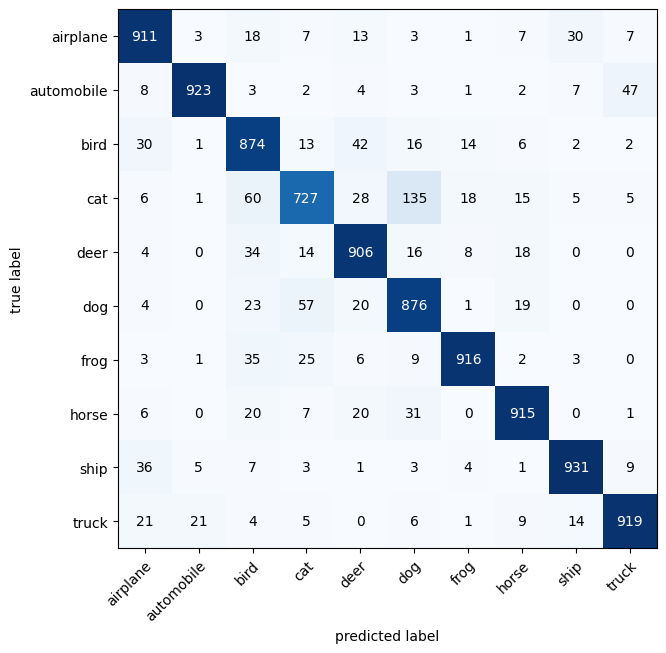

In [90]:
fig,ax = plot_confusion_matrix(
    conf_mat=confmat_tensor.numpy(),     #it works with matplotlib so it likes working with numpy
    class_names=class_names,
    figsize=(10,7)
)

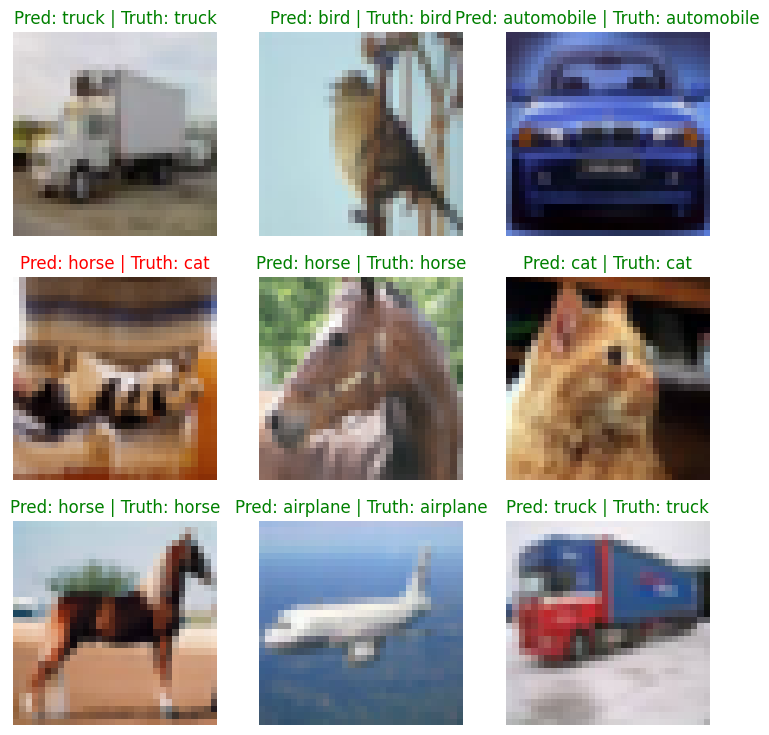

In [91]:
import random
random.seed(42)
test_samples = []
test_labels = []

for sample,label in random.sample(list(test_data),k=9):
    test_samples.append(sample)
    test_labels.append(label)

#Make predictions
pred_probs = make_predictions(model=aug_model_2,
                              data=test_samples)

# Converting the pred probabilities to prediction labels and comparing with the test_labels
pred_labels = pred_probs.argmax(dim=1)

# Plot predictions 
plt.figure(figsize=(9,9))
nrows,ncols=3,3
for i,sample in enumerate(test_samples):
    plt.subplot(nrows,ncols,i+1)

    plt.imshow((sample*std+mean).permute(1,2,0))

    #Get the predicted label
    pred_label = class_names[pred_labels[i]]

    #Get the true label
    true_label = class_names[test_labels[i]]

    #create a title for the plot 
    title_text = f"Pred: {pred_label} | Truth: {true_label}"

    #Check for equality between predicter and truth label along with color coding 
    if pred_label == true_label :
        plt.title(title_text,c='g')   #green text if prediction same
    else:
        plt.title(title_text,c='r')    #red if wrong 

    plt.axis(False)

In [92]:
fig.savefig("Plot_images/augmented_confusion_matrix.png",
            dpi=300,
            bbox_inches="tight")

In [93]:
from pathlib import Path
import shutil

MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

shutil.move(
    "best_model.pth",
    MODEL_PATH / "best_model.pth"
)

WindowsPath('models/best_model.pth')